# PHÂN TÍCH ĐƠN HÀNG, VẬN CHUYỂN & TỐI ƯU HỦY / TRẢ HÀNG
### Bài tập lớn Trực quan hóa dữ liệu · Dataset 8: Amazon Sales Dataset (Synthetic, 2020–2024)

- **Quy mô**: `100.000` giao dịch · `20` cột · `5` năm (`2020–2024`) · Nguồn: Kaggle (`rohiteng/amazon-sales-dataset`)
- **Công cụ**: Python (`pandas`, `scipy`, `Matplotlib`, `Seaborn`, `Plotly HTML`) — áp dụng **Quy trình 7 bước & 5 hướng dẫn Chương 1–3**
- **Lưu ý trung thực**: Dữ liệu tổng hợp (*synthetic*), không phản ánh hoạt động thực tế của Amazon
- **Tài liệu đọc chi tiết khi thuyết trình**: `docs/slide_content.md` · `docs/thuyet_trinh_va_qa.md` · `docs/phan_cong_nhom.md`

## Slide 2 · Thiết lập môi trường & Style Guide chung (TV1 + TV2)
- **Thống nhất toàn nhóm**: Nạp bộ màu **Start-with-gray** (`#94A3B8` nền · `#0F766E` chính · `#DC2626` cảnh báo) và tắt nhiễu mặc định (`despine`, không 3D).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Image, HTML

# Tu dong xac dinh thu muc goc du an (chay duoc tu notebooks/ hoac thu muc goc)
ROOT = Path.cwd().parent if (Path.cwd().name == "notebooks") else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from style_guide import COLORS, apply_style
from importlib import import_module

mod_clean = import_module("01_clean_and_eda")
mod_charts = import_module("02_charts_q1_to_q9")
apply_style()

# Chay lam sach & tinh KPI chuan (hoac nap lai tu data/processed/)
df, clean_log, kpis = mod_clean.run_cleaning_and_eda()
print(f"Đã nạp dữ liệu sạch: {df.shape[0]:,} dòng × {df.shape[1]} cột | Giai đoạn: {clean_log['date_range']['min']} → {clean_log['date_range']['max']}")

Đã nạp dữ liệu sạch: 100,000 dòng × 26 cột | Giai đoạn: 2020-01-01 → 2024-12-29


## Slide 3 · Kiểm định chất lượng, làm sạch & 4 phát hiện từ tệp thật (TV2)
- **Kết quả làm sạch**: `0` ô thiếu · `0` dòng trùng · công thức `TotalAmount` khớp **100%** · giữ nguyên **1.360 ngoại lệ IQR** vì đều là đơn giá trị cao hợp lệ *(Chương 2 Slide 20)*.
- **4 phát hiện khi mở tệp thật**: (1) Có **5 trạng thái** (thêm `Pending`) · (2) Chỉ có **6 Category** · (3) `City/State` Mỹ ghép ngẫu nhiên → dùng **`Country`** · (4) `ProductName` gán độc lập `Category`.

In [2]:
# Tom tat nhanh kiem dinh lam sach & ngoại le IQR
audit_df = pd.DataFrame([
    {"Hạng mục": "Giá trị thiếu (Missing)", "Kết quả": f"{clean_log['missing_values']['total']} ô"},
    {"Hạng mục": "Dòng trùng / OrderID trùng", "Kết quả": f"{clean_log['duplicates']['duplicate_rows']} dòng"},
    {"Hạng mục": "Khớp công thức TotalAmount", "Kết quả": f"100% (sai số tối đa ${clean_log['formula_check']['max_abs_diff']:.2f})"},
    {"Hạng mục": "Ngoại lệ IQR (TotalAmount > $2.863)", "Kết quả": f"{clean_log['iqr_outliers']['TotalAmount']['outlier_count']:,} đơn (1,36%) — giữ nguyên"},
    {"Hạng mục": "Trạng thái đơn thực tế", "Kết quả": f"5 trạng thái: {', '.join(clean_log['synthetic_notes']['order_statuses'])}"},
    {"Hạng mục": "Số Category / Brand / Product / Country", "Kết quả": "6 Category · 10 Brand · 50 SKU · 5 Country"},
])
display(audit_df.style.hide(axis="index"))

Hạng mục,Kết quả
Giá trị thiếu (Missing),0 ô
Dòng trùng / OrderID trùng,0 dòng
Khớp công thức TotalAmount,100% (sai số tối đa $0.01)
Ngoại lệ IQR (TotalAmount > $2.863),"1,360 đơn (1,36%) — giữ nguyên"
Trạng thái đơn thực tế,"5 trạng thái: Cancelled, Delivered, Pending, Returned, Shipped"
Số Category / Brand / Product / Country,6 Category · 10 Brand · 50 SKU · 5 Country


## Slide 4 · Câu 1 — Tổng quan KPI & 5 trạng thái đơn hàng (TV1)
- **Biểu đồ**: Thẻ KPI (4 chỉ số chính góc trên trái) + Thanh tỉ trọng 100% — đọc bức tranh tổng thể trong 5 giây.
- **Chốt ý**: Thất thoát Hủy+Trả (**\$5,63M · 6,13%**) gấp **7,6 lần** tổng phí vận chuyển (**\$740,7K · 0,81%**).

,So_don,Doanh_thu_USD,AOV_USD,Ty_le_don_%
OrderStatus,,,,
Delivered,"74,628","$68,372,677",$916.18,74.63%
Shipped,"15,192","$14,083,629",$927.04,15.19%
Pending,"4,103","$3,737,557",$910.93,4.10%
Returned,"3,049","$2,780,662",$911.99,3.05%
Cancelled,"3,028","$2,851,122",$941.59,3.03%


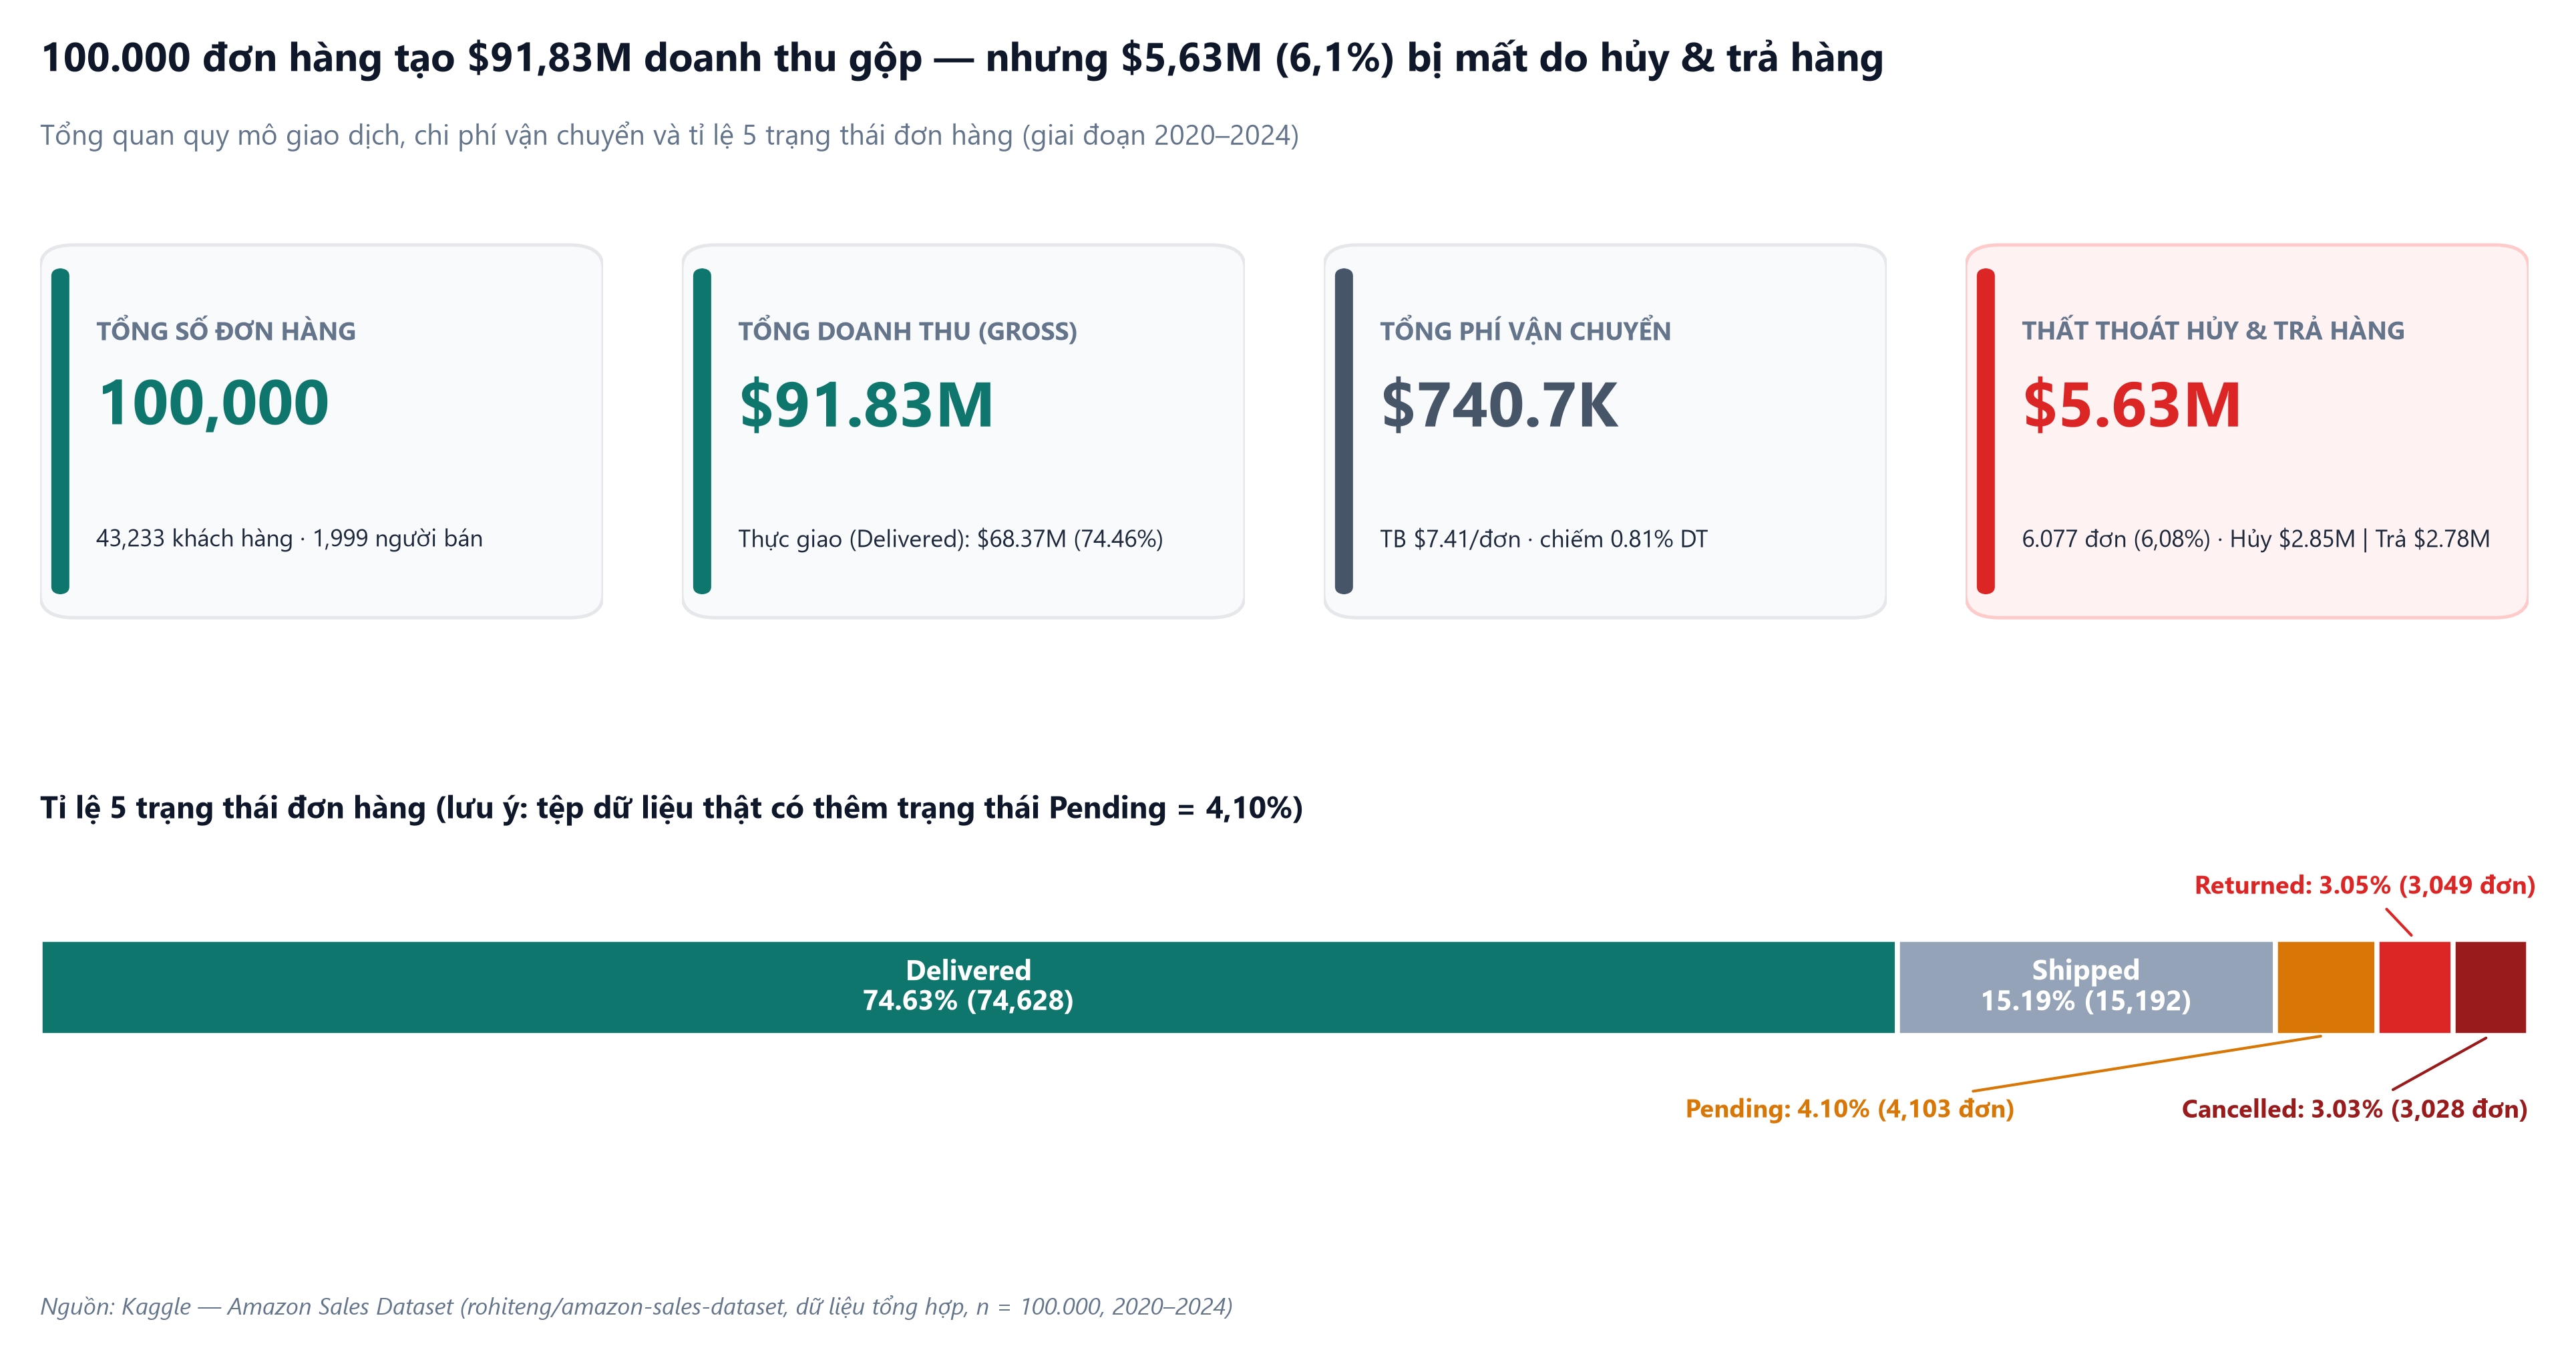

In [3]:
# Tinh nhanh KPI tong quan & ve bieu do Cau 1
q1_tbl = df.groupby("OrderStatus").agg(
    So_don=("OrderID", "count"),
    Doanh_thu_USD=("TotalAmount", "sum"),
    AOV_USD=("TotalAmount", "mean"),
).sort_values("So_don", ascending=False)
q1_tbl["Ty_le_don_%"] = (q1_tbl["So_don"] / len(df) * 100).round(2)
display(q1_tbl.style.format({"So_don": "{:,}", "Doanh_thu_USD": "${:,.0f}", "AOV_USD": "${:,.2f}", "Ty_le_don_%": "{:.2f}%"}))

p1 = mod_charts.plot_q1(df, kpis)
display(Image(filename=str(p1), width=920))

## Slide 5 · Câu 2 — Doanh thu & số đơn theo tháng và năm (TV2)
- **Biểu đồ**: 2 biểu đồ đường xếp dọc chung trục thời gian (**tránh lỗi 2 trục Y — Chương 2 Slide 41**) + cột gốc `0` theo năm.
- **Chốt ý**: Quy mô rất ổn định (~\$18,4M/năm · CV tháng 4,21%); **đáy lặp lại mỗi tháng 2** do chỉ có 28–29 ngày.

Year,So_don,Doanh_thu_USD,YoY_%
2020,"20,066","$18,529,864",—
2021,"19,890","$18,248,575",-1.52%
2022,"20,078","$18,367,248",+0.65%
2023,"20,096","$18,513,912",+0.80%
2024,"19,870","$18,166,048",-1.88%


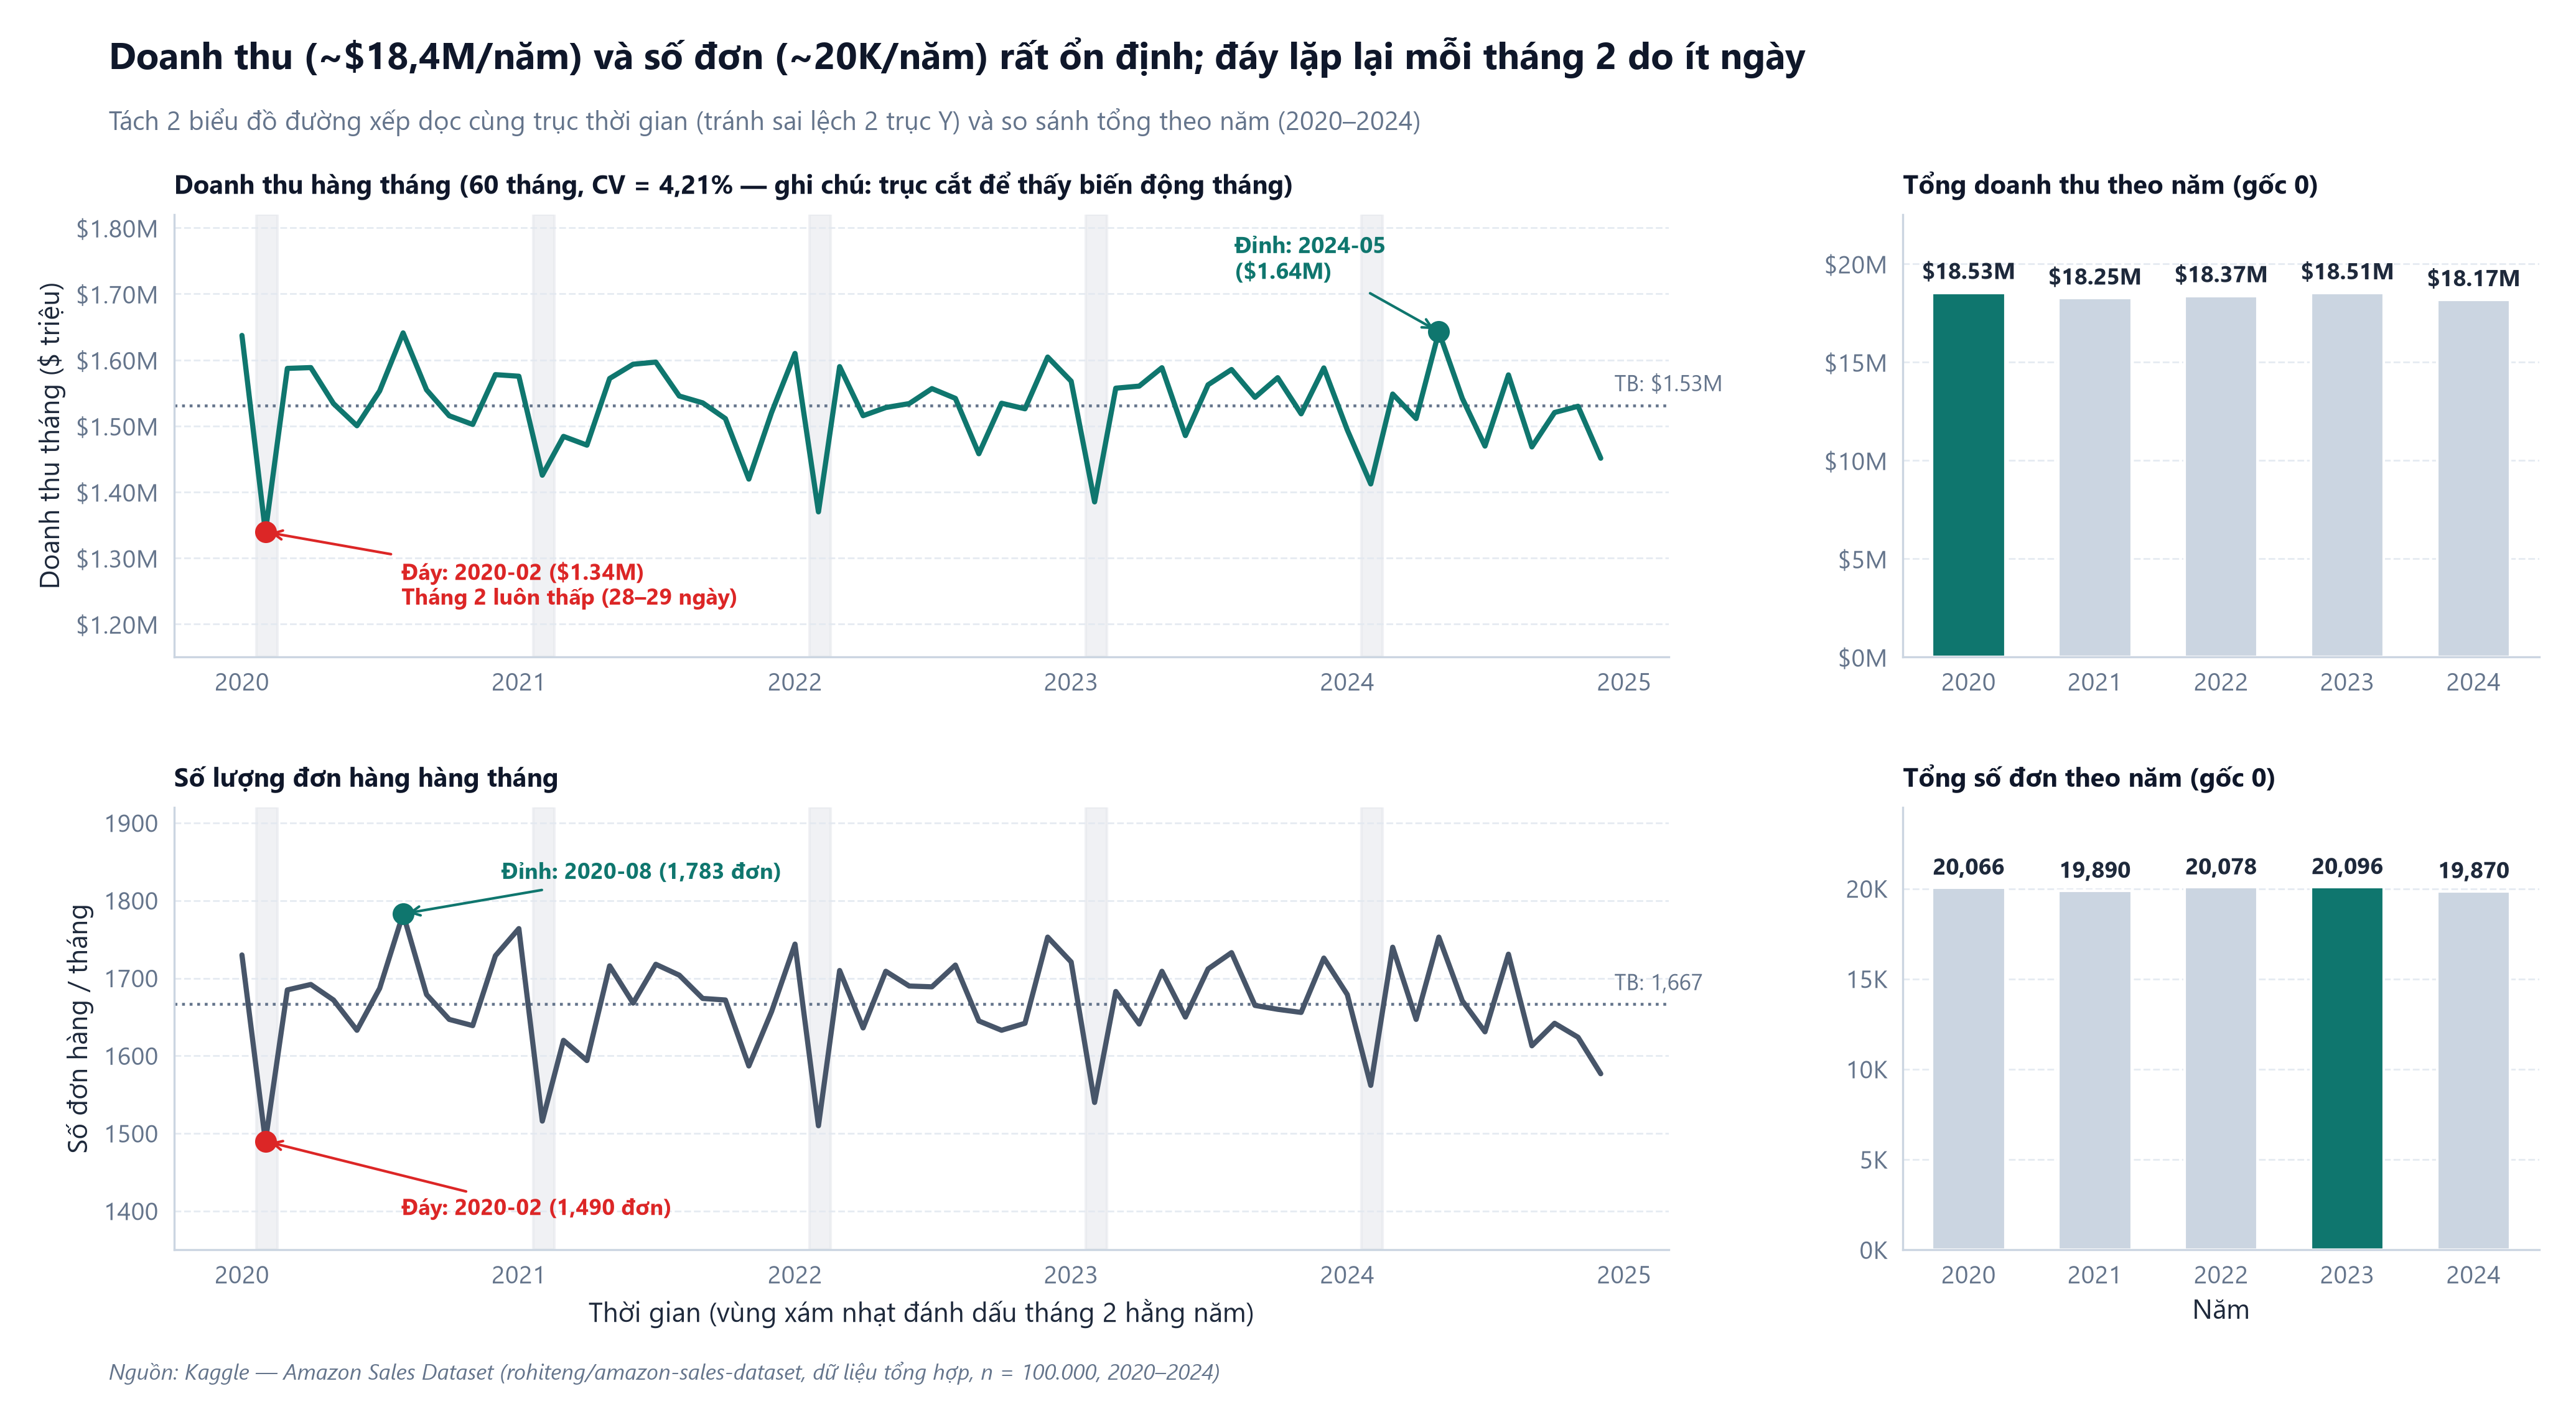

In [4]:
# Tong hop theo nam & ve bieu do Cau 2
yr_tbl = df.groupby("Year").agg(So_don=("OrderID", "count"), Doanh_thu_USD=("TotalAmount", "sum")).reset_index()
yr_tbl["YoY_%"] = (yr_tbl["Doanh_thu_USD"].pct_change() * 100).round(2)
display(yr_tbl.style.hide(axis="index").format({"So_don": "{:,}", "Doanh_thu_USD": "${:,.0f}", "YoY_%": "{:+.2f}%"}, na_rep="—"))

p2 = mod_charts.plot_q2(df, kpis)
display(Image(filename=str(p2), width=940))

## Slide 6 · Câu 3 ⭐ (Trọng tâm 1/4) — Cơ cấu 5 trạng thái qua 5 năm (TV3)
- **Biểu đồ**: Cột chồng 100% theo năm + Cột ngang xếp hạng (dễ đọc hơn Donut theo **thang Cleveland–McGill**).
- **Chốt ý**: Tỉ lệ Hủy+Trả đi ngang **~6,1% suốt 5 năm** ($p = 0,58$) và đơn `Cancelled` có **AOV cao nhất (\$942)** → rò rỉ hệ thống cần chặn ở đơn giá trị cao.

Kiểm định Chi-square (Năm × Trạng thái): chi2 = 14.19, p = 0.5845 → Cơ cấu ổn định suốt 5 năm


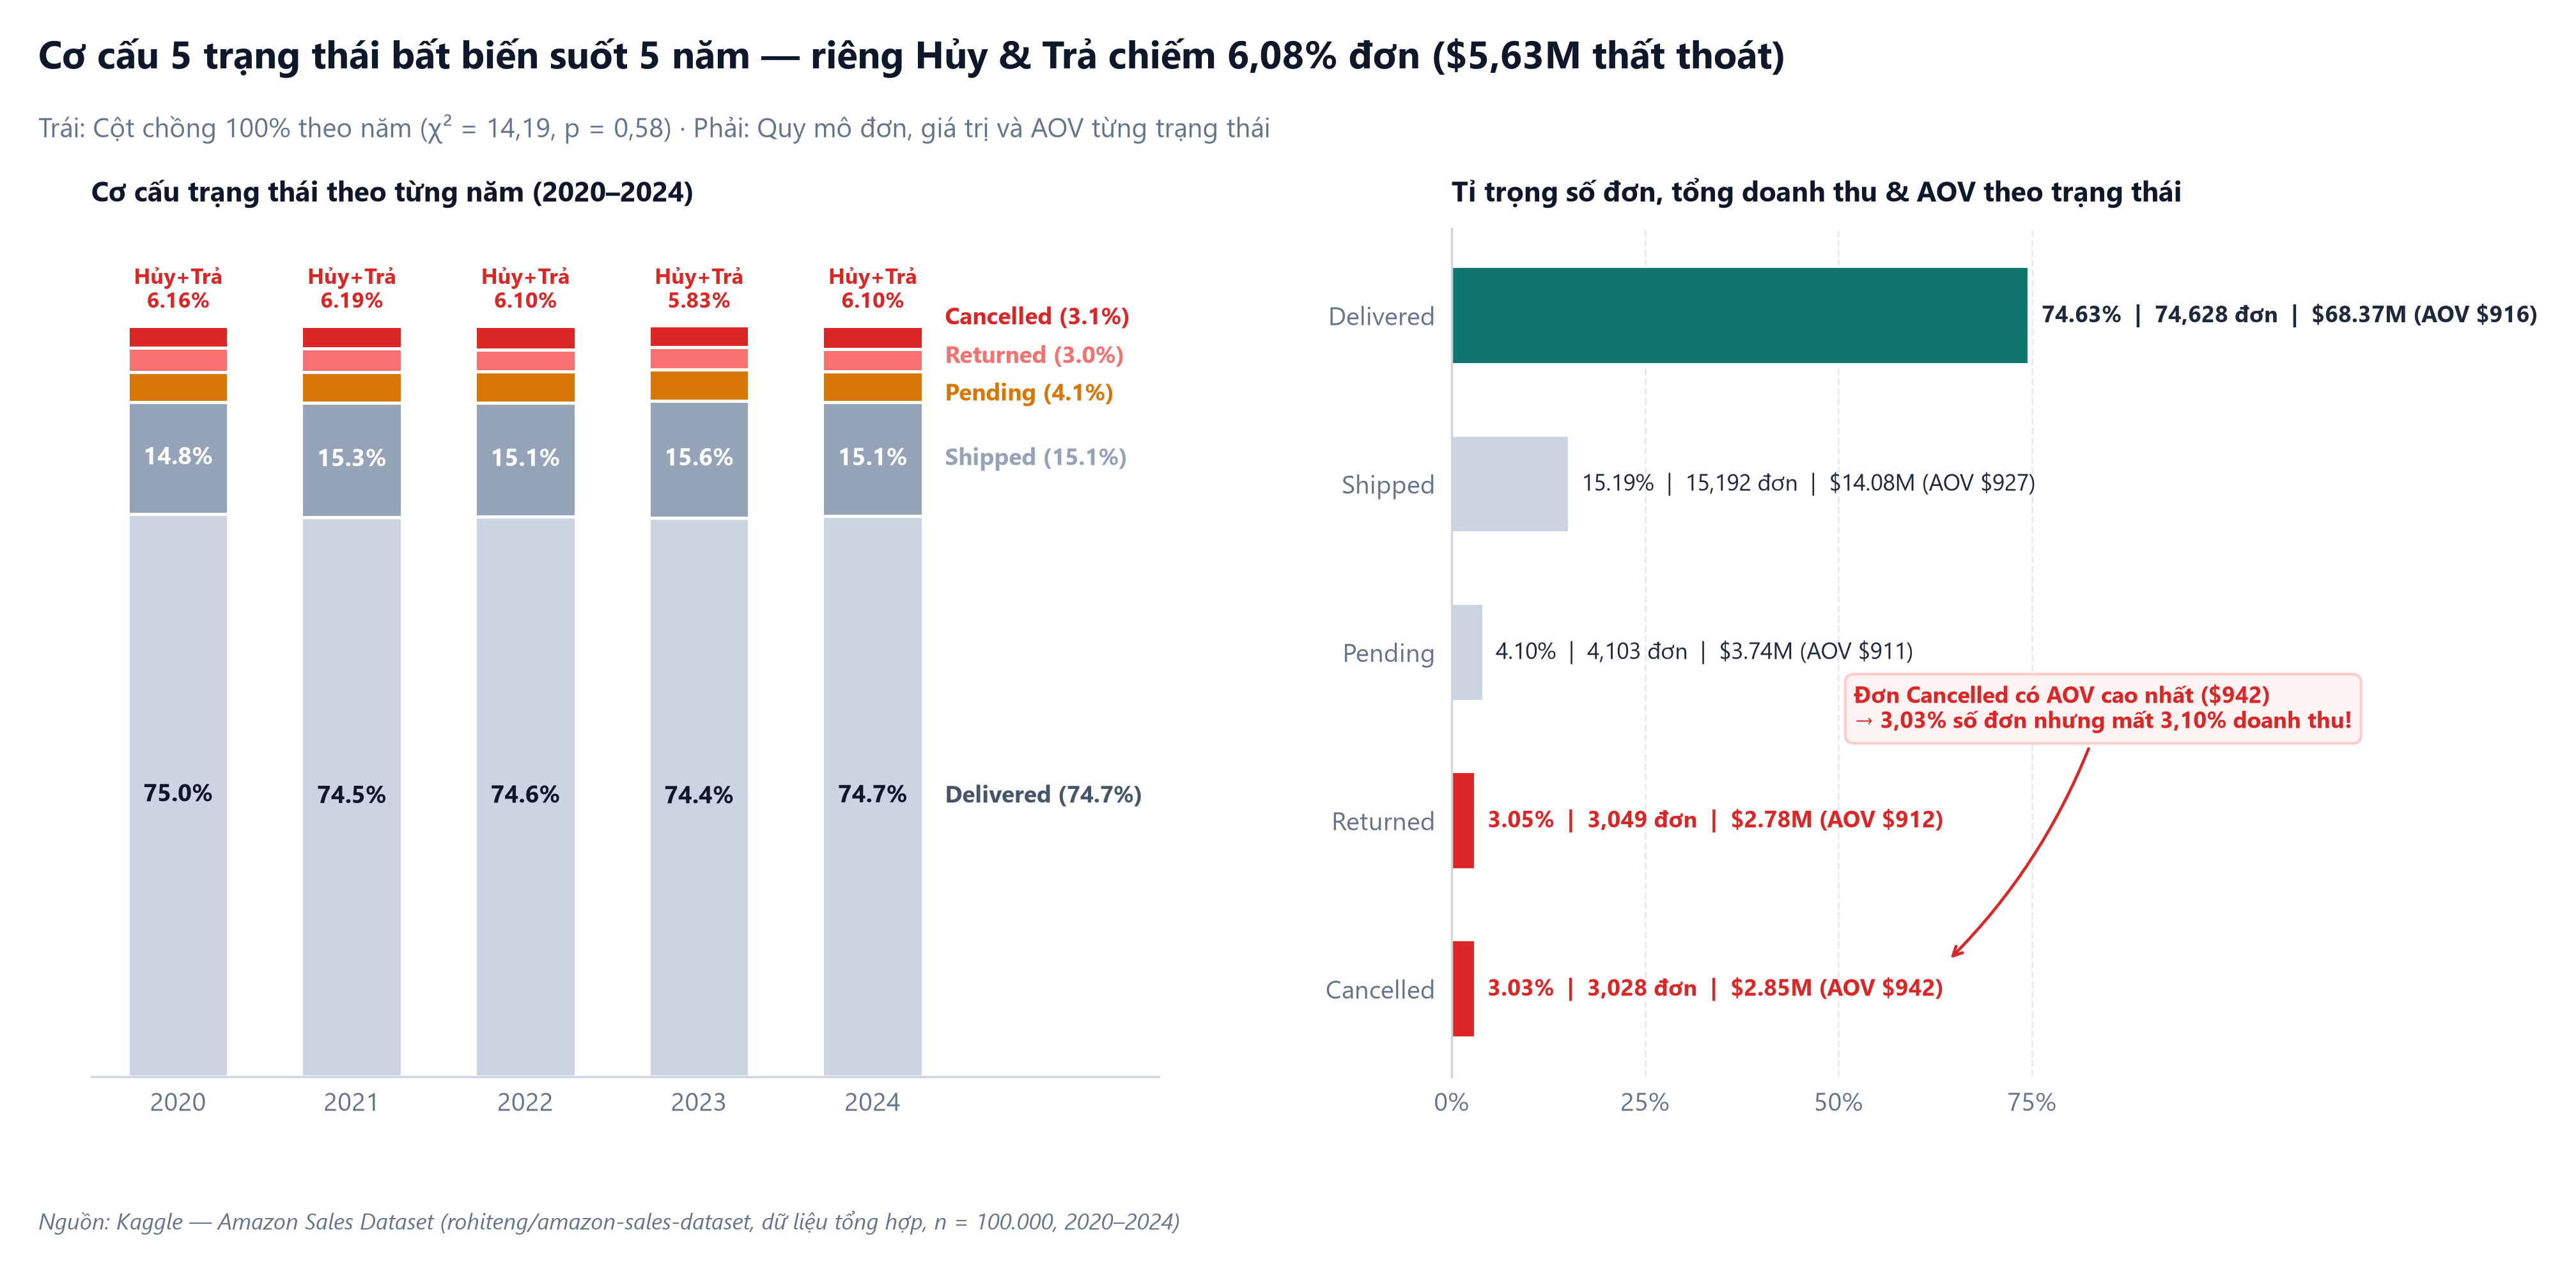

In [5]:
# Kiem dinh on dinh co cau trang thai qua 5 nam (Chi-square) & ve Cau 3
ct_yr = pd.crosstab(df["Year"], df["OrderStatus"])
chi2_st, p_st, _, _ = stats.chi2_contingency(ct_yr)
print(f"Kiểm định Chi-square (Năm × Trạng thái): chi2 = {chi2_st:.2f}, p = {p_st:.4f} → Cơ cấu ổn định suốt 5 năm")

p3 = mod_charts.plot_q3(df, kpis)
display(Image(filename=str(p3), width=940))

## Slide 7 · Câu 4 — Doanh thu theo 6 nhóm sản phẩm & Top 10 SKU (TV3)
- **Biểu đồ**: Cột ngang xếp hạng (trục từ `0`, nhãn dài dễ đọc); đối chiếu tệp thật chỉ có **6 Category** nên bổ sung **Top 10 SKU**.
- **Chốt ý**: `Electronics` dẫn đầu (**\$15,58M · 17,0%**), 6 nhóm rất cân bằng (+2,8%); **`Dress Shirt`** vừa nằm Top 6 doanh thu vừa thuộc Top 3 trả hàng.

,So_don,Doanh_thu_USD,Ty_trong_%
Category,,,
Electronics,"16,853","$15,584,217",16.97%
Sports & Outdoors,"16,804","$15,345,572",16.71%
Books,"16,752","$15,261,837",16.62%
Clothing,"16,439","$15,253,398",16.61%
Toys & Games,"16,542","$15,216,685",16.57%
Home & Kitchen,"16,610","$15,163,939",16.51%


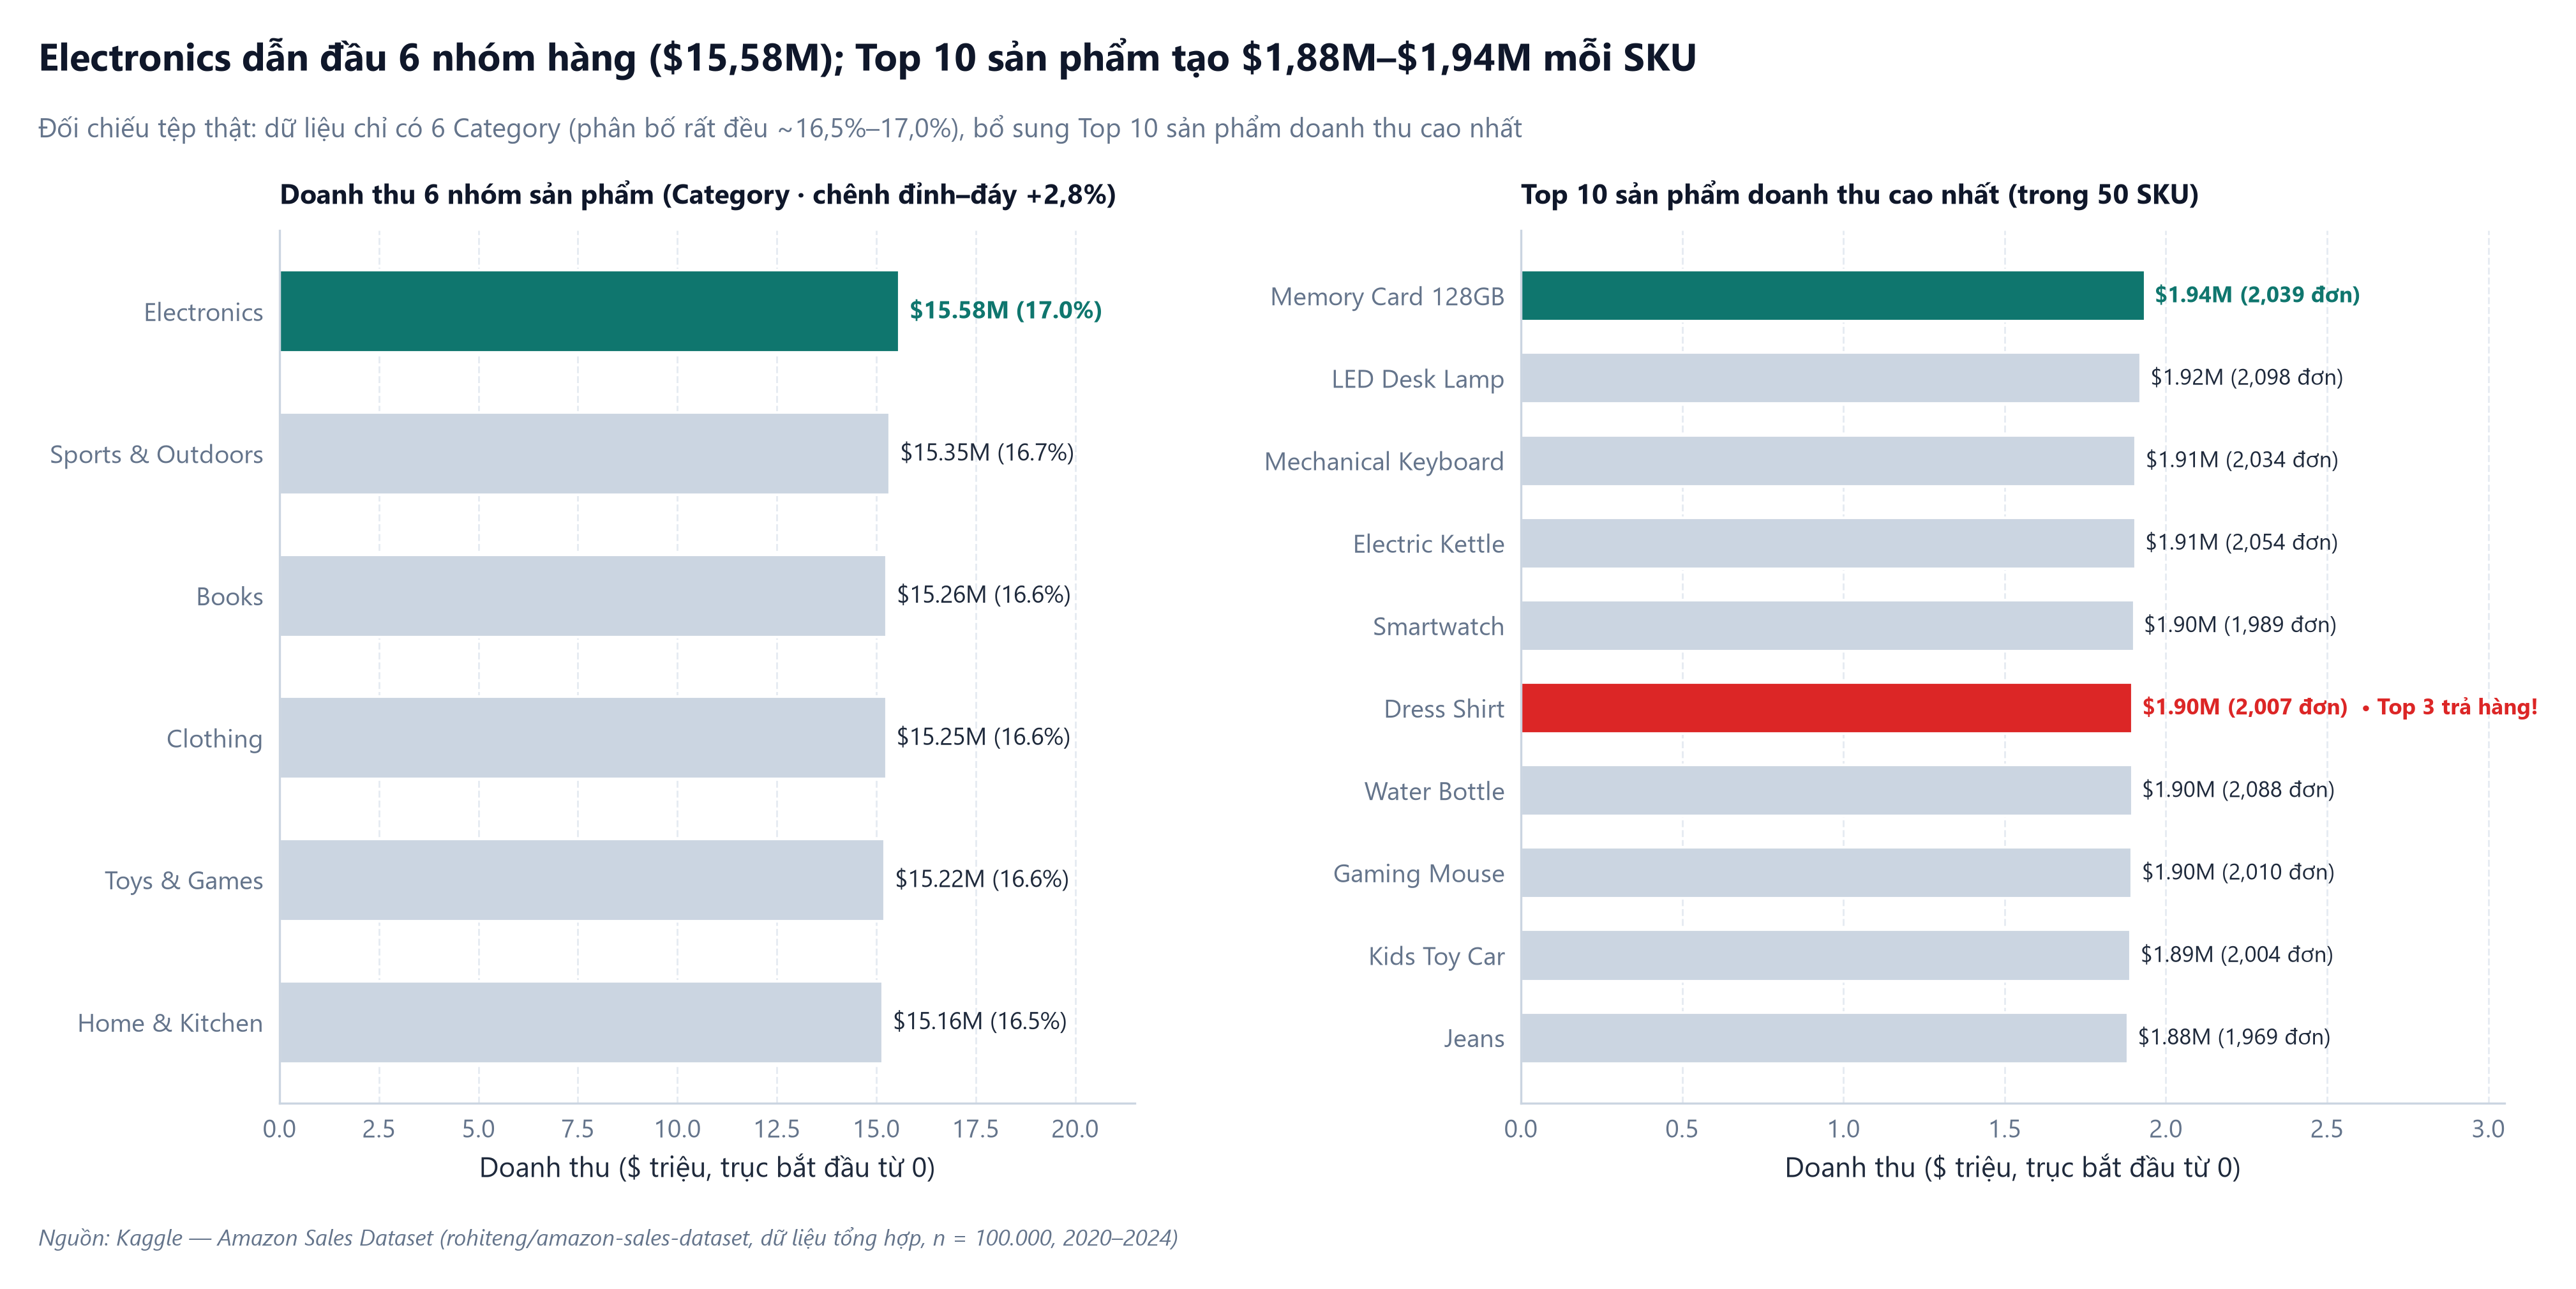

In [6]:
# Xep hang 6 Category theo doanh thu & ve bieu do Cau 4
cat_rev = df.groupby("Category").agg(So_don=("OrderID", "count"), Doanh_thu_USD=("TotalAmount", "sum")).sort_values("Doanh_thu_USD", ascending=False)
cat_rev["Ty_trong_%"] = (cat_rev["Doanh_thu_USD"] / df["TotalAmount"].sum() * 100).round(2)
display(cat_rev.style.format({"So_don": "{:,}", "Doanh_thu_USD": "${:,.0f}", "Ty_trong_%": "{:.2f}%"}))

p4 = mod_charts.plot_q4(df, kpis)
display(Image(filename=str(p4), width=940))

## Slide 8 · Câu 5 — Doanh thu theo khu vực khách hàng (TV4)
- **Biểu đồ**: Cột ngang xếp hạng + Dot plot AOV (tĩnh) kết hợp **Bản đồ Choropleth tương tác (Plotly)** theo `Country`.
- **Chốt ý**: **Hoa Kỳ chiếm 70,0% (\$64,31M)** — gấp **2,34×** 4 nước còn lại; AOV tương đương (~\$915–\$922) → chênh lệch 100% do số đơn.

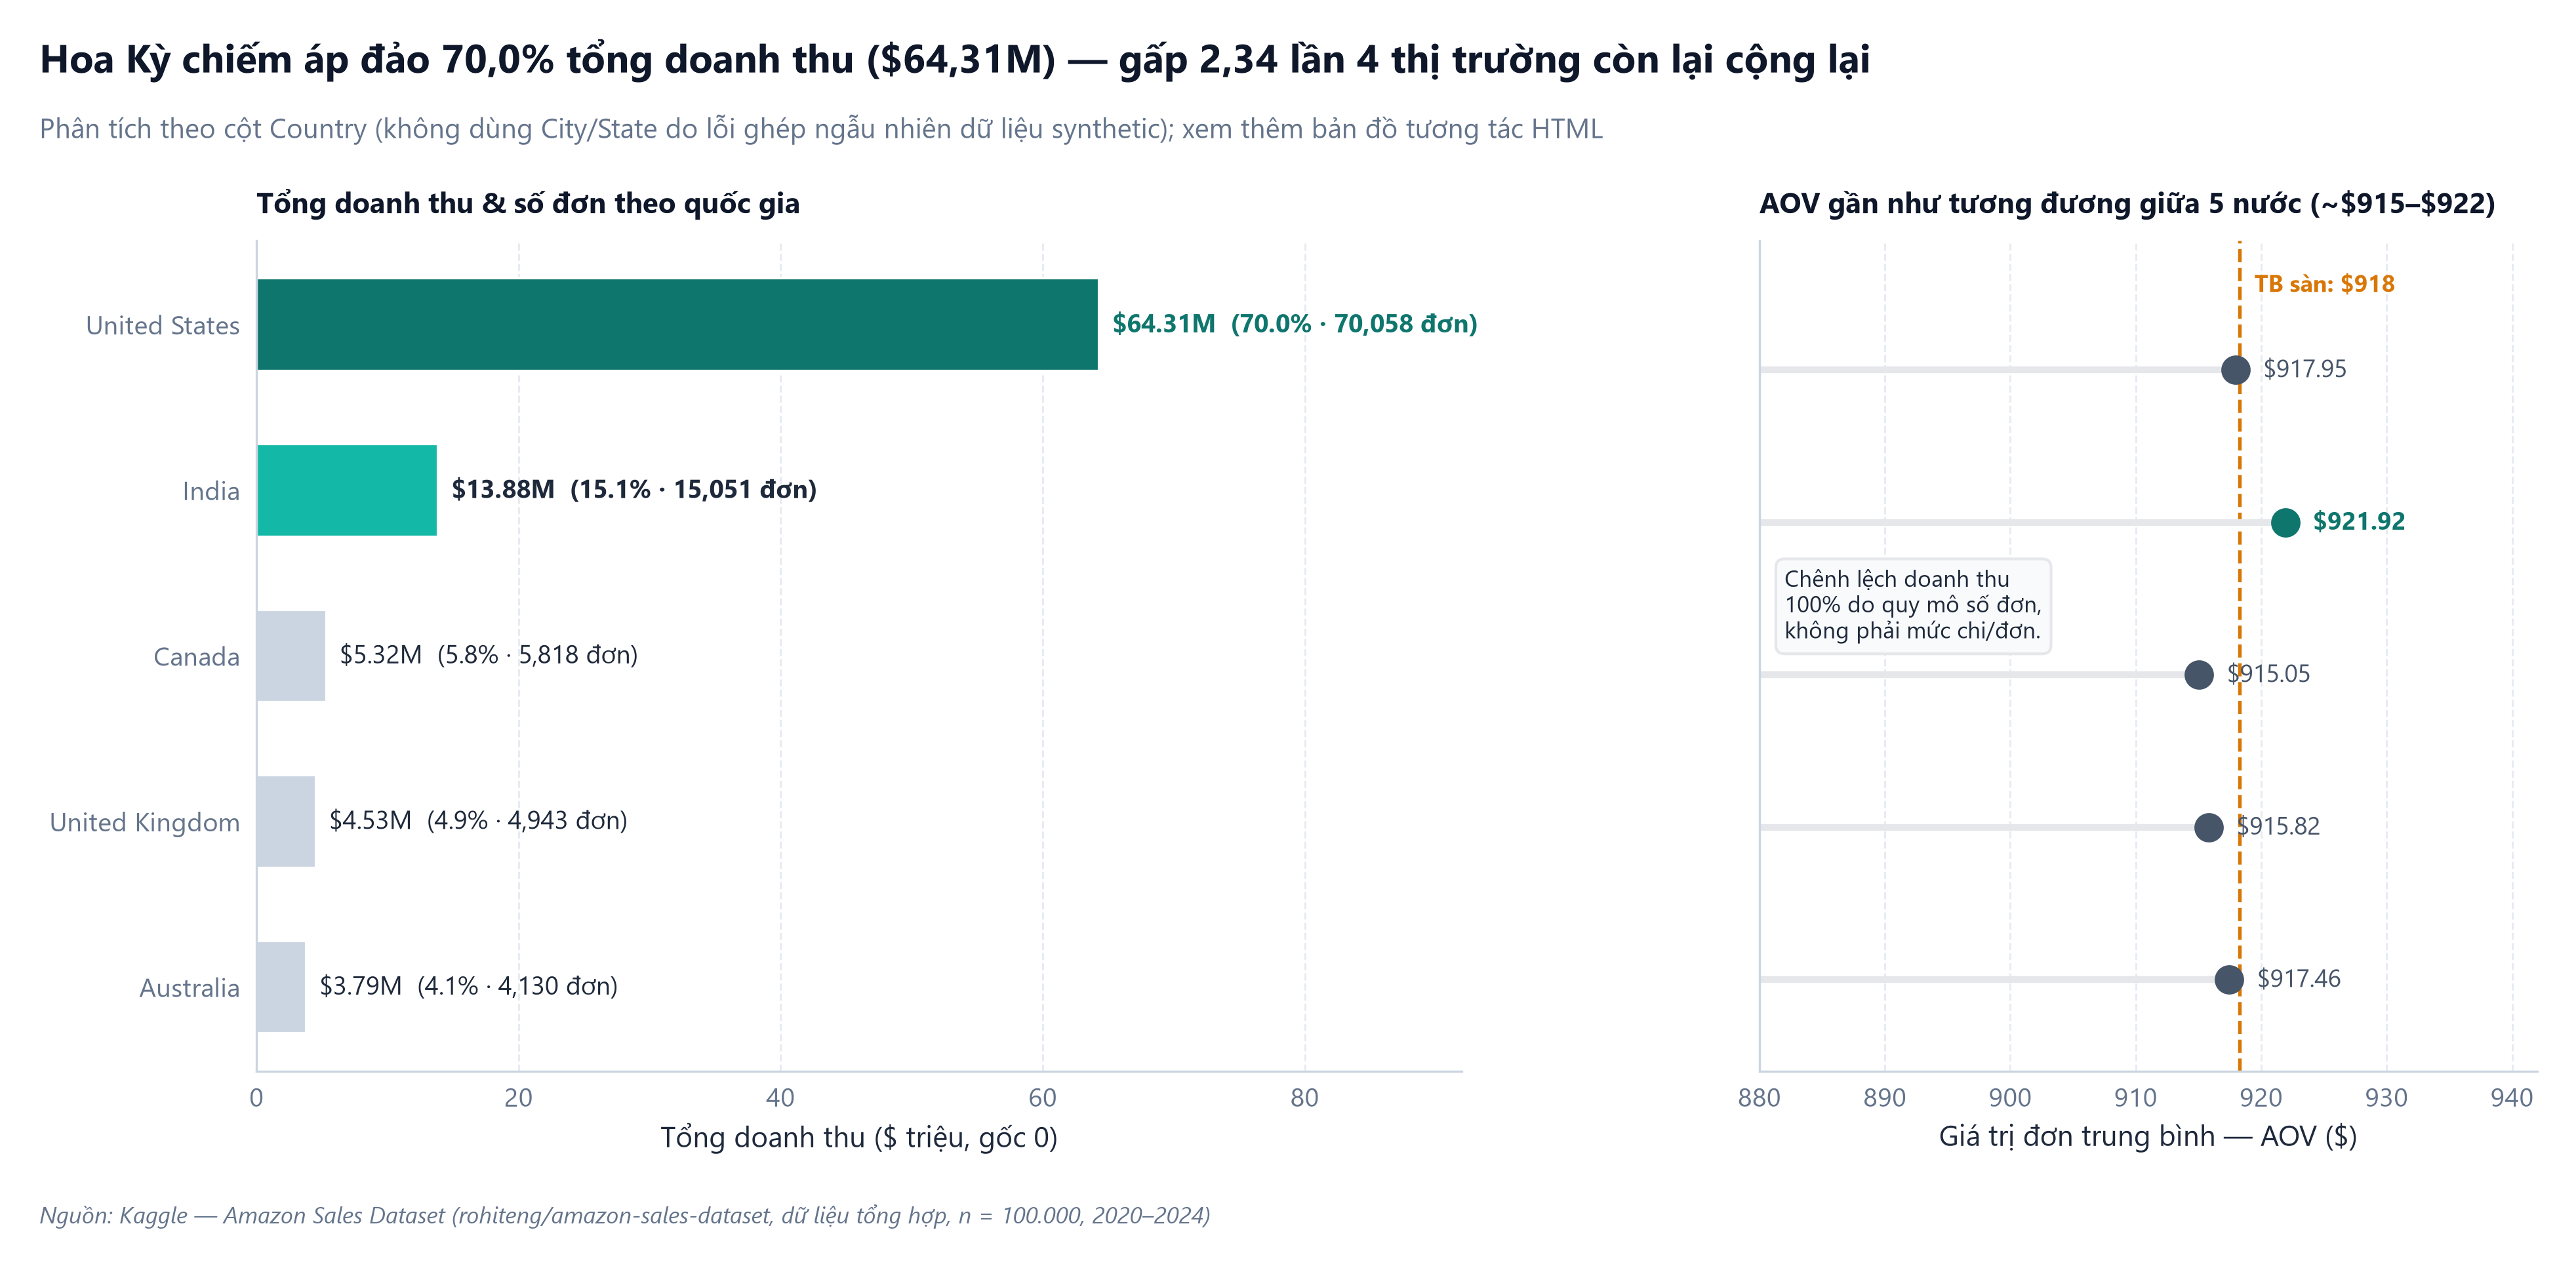

In [7]:
# Bieu do tinh Cau 5 (Cot ngang + AOV)
p5 = mod_charts.plot_q5(df, kpis)
display(Image(filename=str(p5), width=940))

# Ban do Choropleth tuong tac truc tiep trong Notebook (di chuot xem chi tiet)
co_df = pd.DataFrame(kpis["q5"]["countries"])
co_df["iso3"] = co_df["Country"].map({"United States": "USA", "India": "IND", "Canada": "CAN", "United Kingdom": "GBR", "Australia": "AUS"})
co_df["rev_m"] = (co_df["revenue"] / 1e6).round(2)

fig_map = px.choropleth(
    co_df, locations="iso3", color="rev_m", hover_name="Country",
    hover_data={"iso3": False, "rev_m": ":.2f", "rev_pct": ":.2f", "orders": ":,", "avg_order": ":.2f"},
    color_continuous_scale=["#CCFBF1", "#5EEAD4", "#14B8A6", "#0F766E", "#134E4A"],
    labels={"rev_m": "Doanh thu ($M)", "rev_pct": "Tỉ trọng (%)", "orders": "Số đơn", "avg_order": "AOV ($)"},
    title="Bản đồ tương tác: Hoa Kỳ ($64,31M) & Ấn Độ ($13,88M) chiếm 85,1% tổng doanh thu",
)
fig_map.update_geos(showframe=False, showcoastlines=True, coastlinecolor="#CBD5E1", projection_type="natural earth")
fig_map.update_layout(template="plotly_white", height=420, margin=dict(l=10, r=10, t=55, b=10))
fig_map.show()

## Slide 9 · Câu 6 ⭐ (Trọng tâm 2/4) — Tỉ lệ Hủy & Trả theo nhóm sản phẩm (TV5)
- **Biểu đồ**: Cột nhóm ngang **tách riêng `Cancel %` (trước giao) và `Return %` (sau giao)** + cột thiệt hại tiền mặt.
- **Chốt ý**: `Home & Kitchen` cao nhất tổng Hủy+Trả (**6,27% · \$984K**); `Electronics` cao nhất tỉ lệ Hủy (**3,23%**); $p = 0,84$ → vấn đề trải đều toàn sàn.

Kiểm định Chi-square (Category × Hủy/Trả): chi2 = 2.05, p = 0.8417


Category,orders,cancel_pct,return_pct,combined_pct,lost_rev
Home & Kitchen,"16,610",3.06%,3.21%,6.27%,"$984,133"
Books,"16,752",2.98%,3.12%,6.11%,"$931,528"
Toys & Games,"16,542",3.10%,2.99%,6.09%,"$963,365"
Electronics,"16,853",3.23%,2.82%,6.05%,"$920,604"
Sports & Outdoors,"16,804",2.96%,3.08%,6.04%,"$911,447"
Clothing,"16,439",2.84%,3.07%,5.91%,"$920,708"


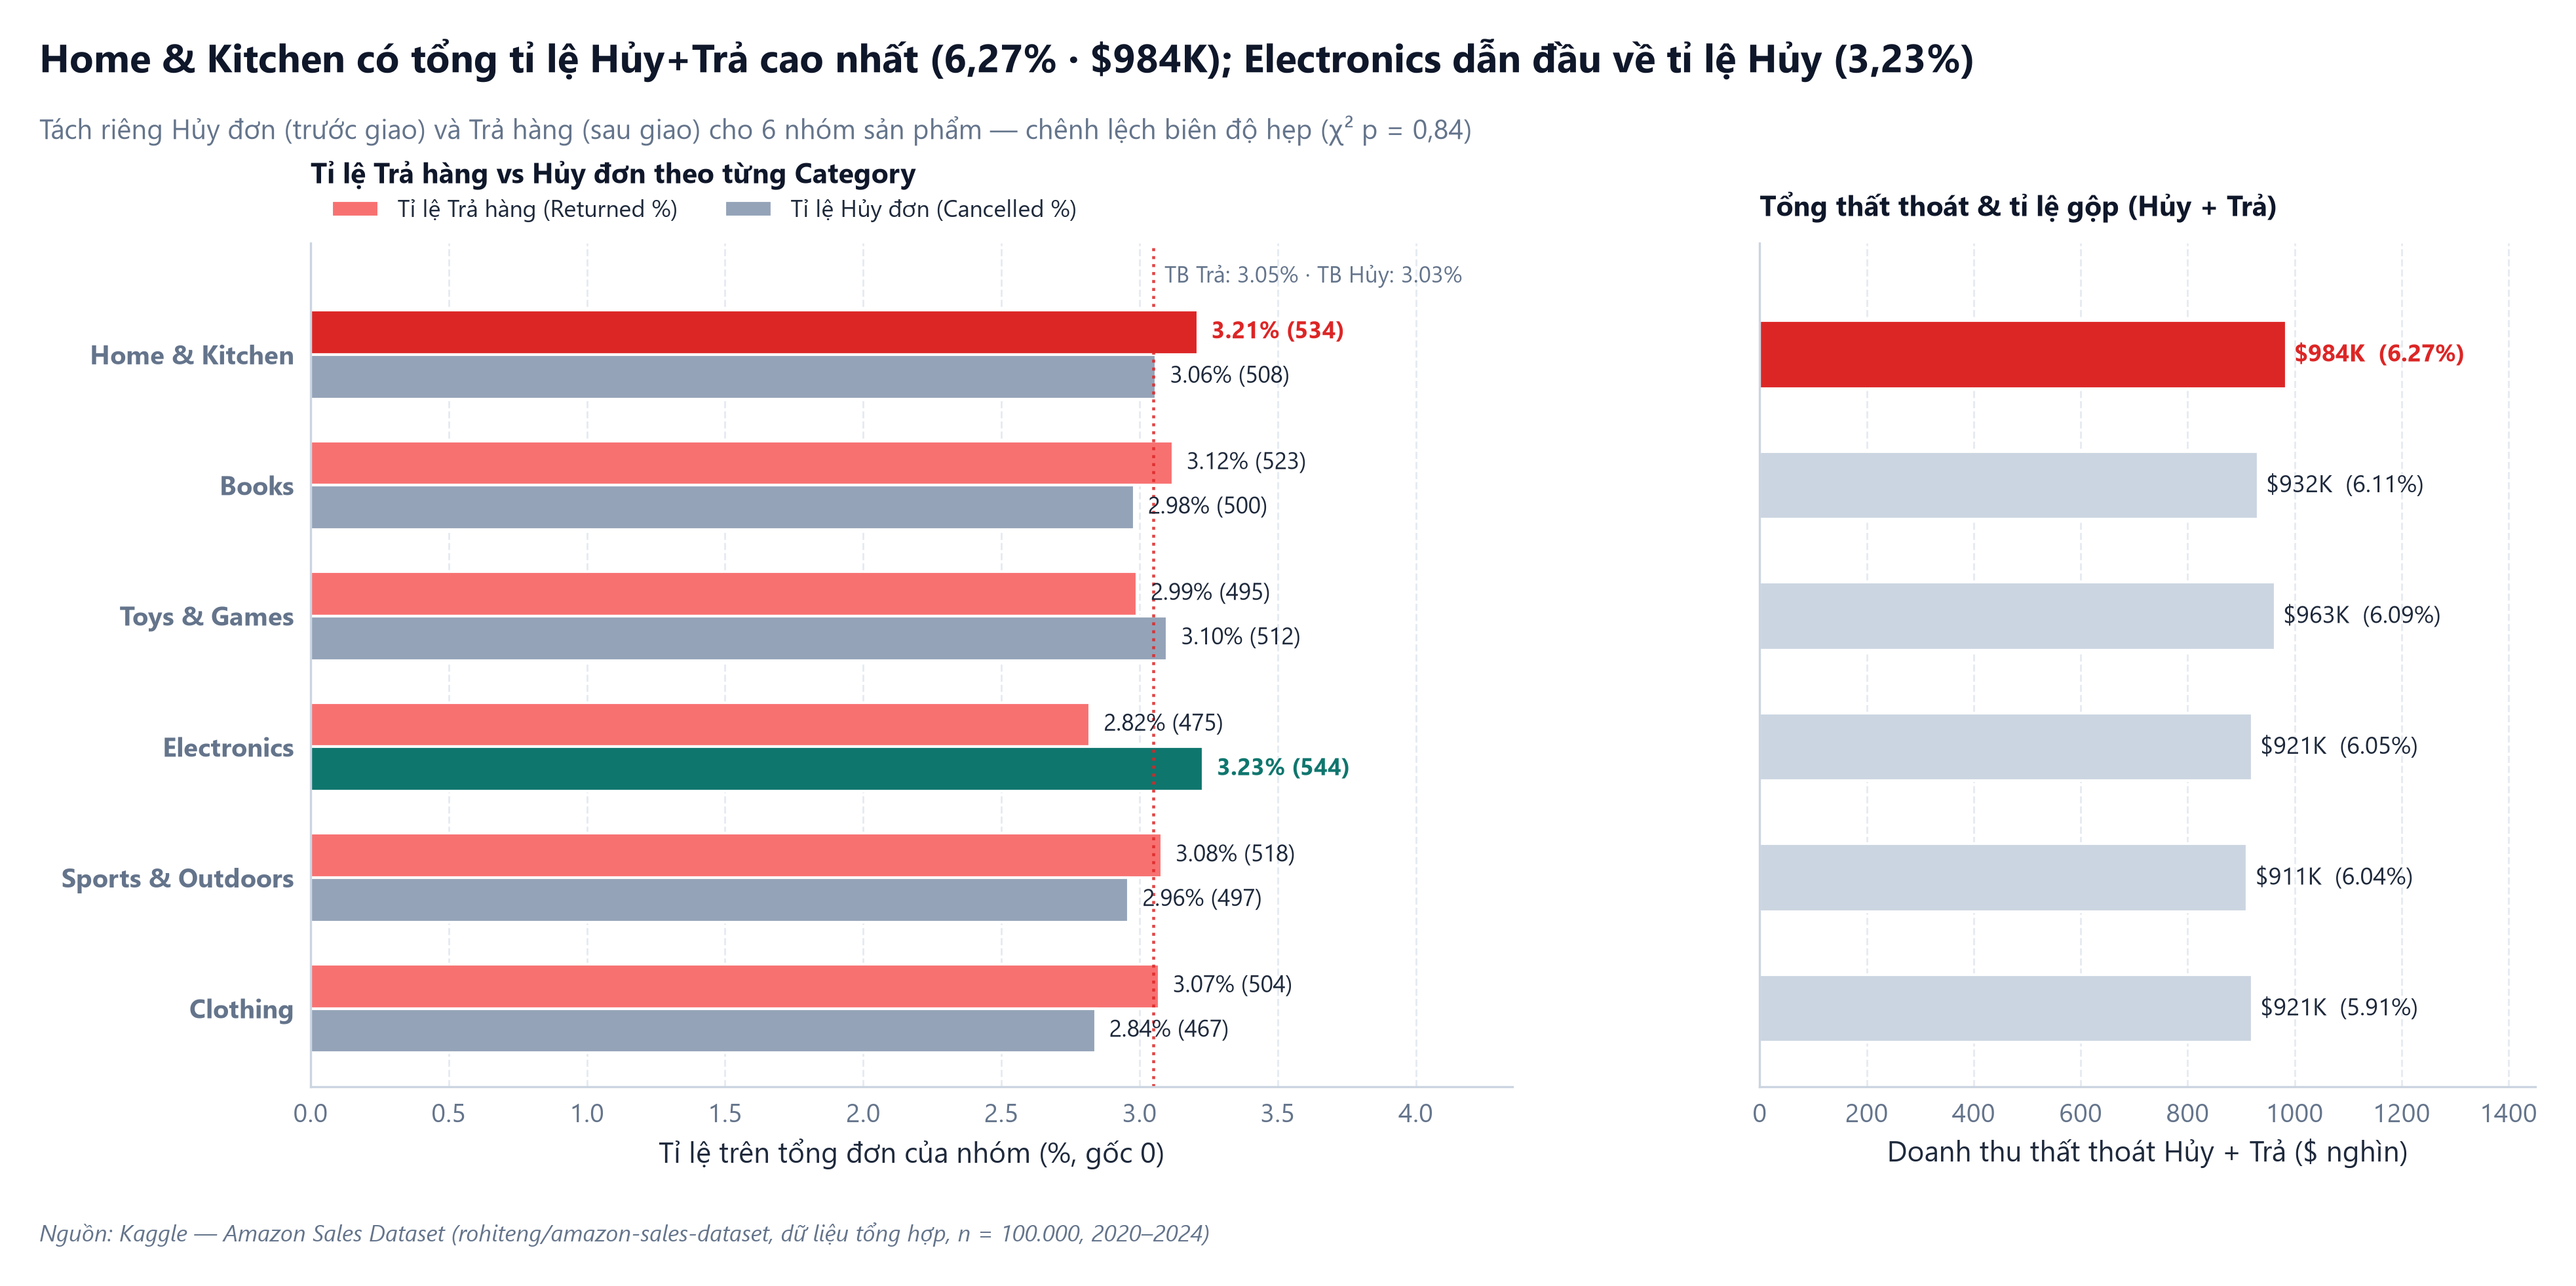

In [8]:
# Tinh ti le Huy & Tra theo Category + kiem dinh Chi-square & ve Cau 6
q6_df = pd.DataFrame(kpis["q6"]["by_category"])[["Category", "orders", "cancel_pct", "return_pct", "combined_pct", "lost_rev"]]
print(f"Kiểm định Chi-square (Category × Hủy/Trả): chi2 = {kpis['q6']['chi2_test']['chi2']:.2f}, p = {kpis['q6']['chi2_test']['p_value']:.4f}")
display(q6_df.style.hide(axis="index").format({"orders": "{:,}", "cancel_pct": "{:.2f}%", "return_pct": "{:.2f}%", "combined_pct": "{:.2f}%", "lost_rev": "${:,.0f}"}))

p6 = mod_charts.plot_q6(df, kpis)
display(Image(filename=str(p6), width=940))

## Slide 10 · Câu 7 — Chi phí vận chuyển theo quốc gia & giá trị đơn (TV4)
- **Biểu đồ**: Boxplot theo quốc gia (`Seaborn`) + **Hexbin mật độ** chống chồng điểm 100K dòng + cột gánh nặng phí ship.
- **Chốt ý**: Phí ship đồng nhất ~\$7,4/đơn (ANOVA $p = 0,57$, $r = 0,039$) → đơn nhỏ **`<$250` chịu 6,86% giá trị đơn** (gấp **18×** đơn `>$1.500`).

ANOVA 5 quốc gia: F = 0.73, p = 0.5691
Tương quan Pearson (TotalAmount vs ShippingCost): r = 0.0394


OrderBucket,orders,mean_ship,median_ship,mean_ship_pct,median_ship_pct
<$250,"17,941",$6.77,$6.37,6.86%,5.34%
$250–500,"19,357",$7.53,$7.48,2.09%,2.01%
$500–1K,"25,058",$7.55,$7.53,1.09%,1.04%
$1K–1.5K,"16,593",$7.51,$7.53,0.62%,0.61%
>$1.5K,"21,051",$7.57,$7.59,0.38%,0.37%


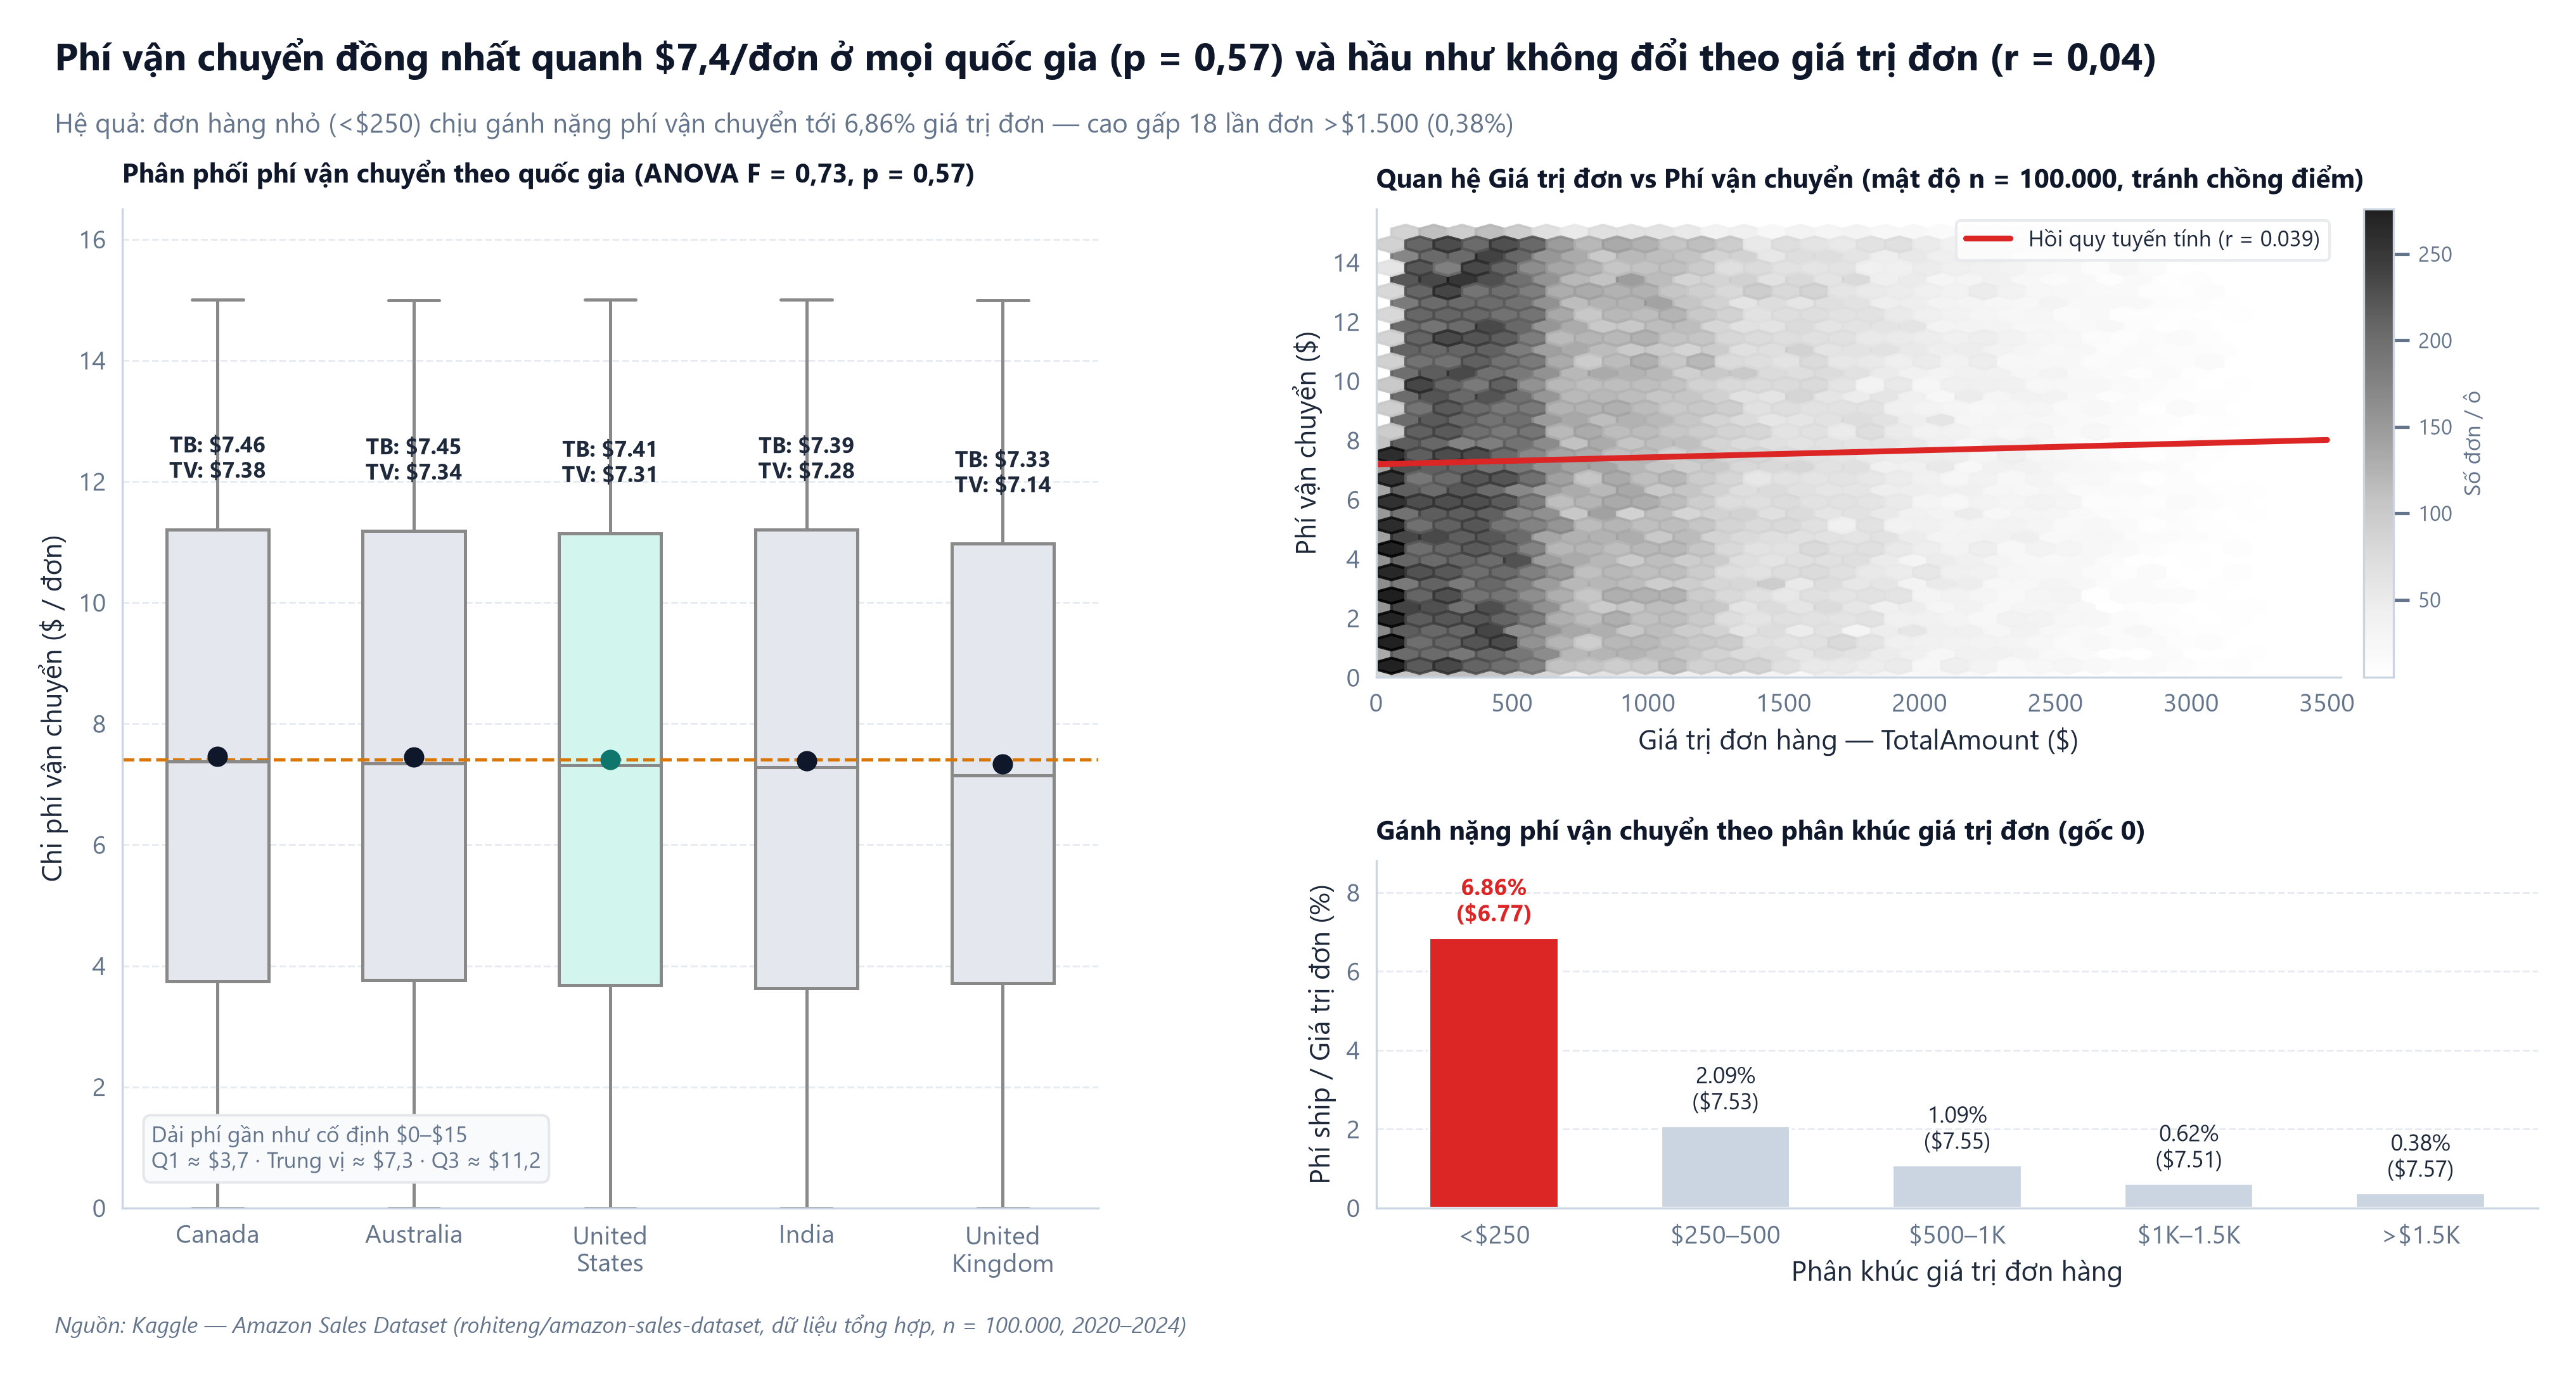

In [9]:
# Tom tat thong ke phi ship theo nhom gia tri don & ve Cau 7
print(f"ANOVA 5 quốc gia: F = {kpis['q7']['anova_country_ship']['f_stat']:.2f}, p = {kpis['q7']['anova_country_ship']['p_value']:.4f}")
print(f"Tương quan Pearson (TotalAmount vs ShippingCost): r = {kpis['q7']['corr_total_amount_vs_ship']['pearson_r']:.4f}")
display(pd.DataFrame(kpis["q7"]["by_order_value_bucket"]).style.hide(axis="index").format(
    {"orders": "{:,}", "mean_ship": "${:.2f}", "median_ship": "${:.2f}", "mean_ship_pct": "{:.2f}%", "median_ship_pct": "{:.2f}%"}
))

p7 = mod_charts.plot_q7(df, kpis)
display(Image(filename=str(p7), width=940))

## Slide 11 · Câu 8 ⭐ (Trọng tâm 3/4) — Thanh toán & Rủi ro Hủy/Trả (TV5)
- **Biểu đồ**: Cột nhóm tỉ lệ % đặt cạnh cột **Thiệt hại tiền mặt (\$M)** — tránh bẫy chỉ nhìn tỉ lệ % mà bỏ qua quy mô tiền.
- **Chốt ý**: `COD` hủy cao nhất (**3,17%**), nhưng **`Credit + Debit Card`** chiếm **55,1% tổng tiền mất (\$3,10M)**; `UPI` an toàn nhất (5,85%).

Kiểm định Chi-square (Payment × Hủy/Trả): chi2 = 2.48, p = 0.7790


PaymentMethod,orders,order_pct,cancel_pct,return_pct,combined_pct,lost_rev
Amazon Pay,"15,017",15.0%,3.07%,3.14%,6.21%,"$833,737"
Credit Card,"35,038",35.0%,3.09%,3.07%,6.16%,"$1,987,819"
Net Banking,"9,927",9.9%,2.93%,3.15%,6.08%,"$578,872"
Cash on Delivery,"4,928",4.9%,3.17%,2.90%,6.07%,"$279,315"
Debit Card,"20,024",20.0%,2.96%,3.04%,6.00%,"$1,116,676"
UPI,"15,066",15.1%,2.95%,2.90%,5.85%,"$835,364"


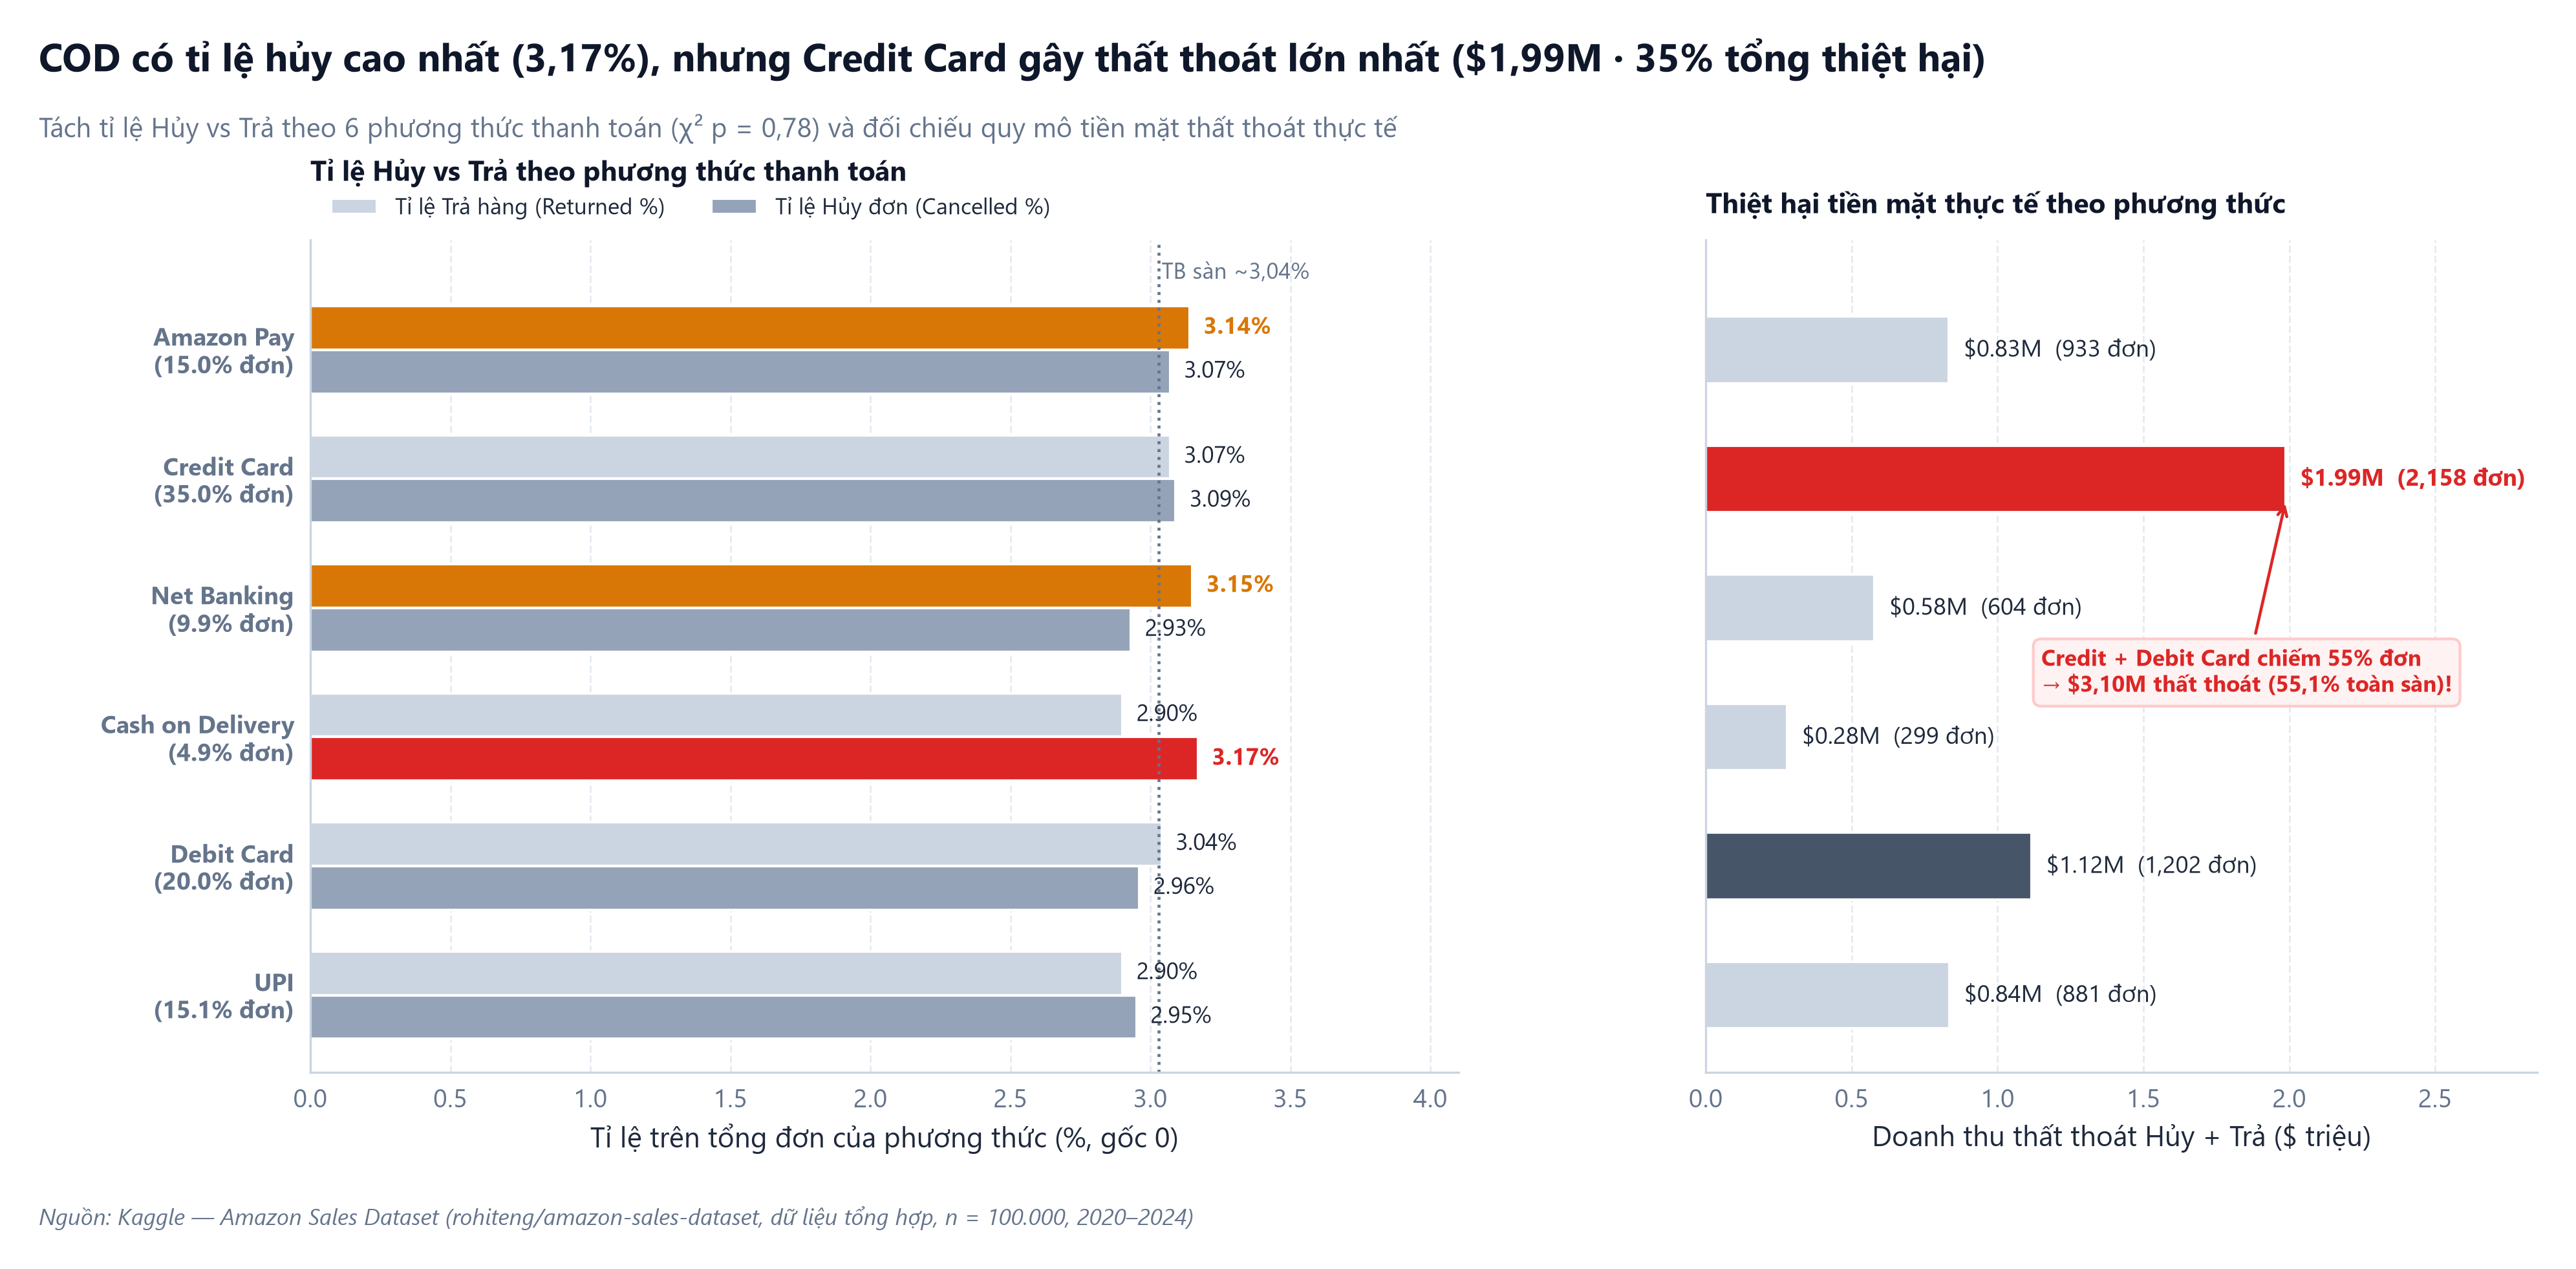

In [10]:
# Bang tong hop theo phuong thuc thanh toan & ve Cau 8
q8_df = pd.DataFrame(kpis["q8"]["by_payment"])[["PaymentMethod", "orders", "order_pct", "cancel_pct", "return_pct", "combined_pct", "lost_rev"]]
print(f"Kiểm định Chi-square (Payment × Hủy/Trả): chi2 = {kpis['q8']['chi2_test']['chi2']:.2f}, p = {kpis['q8']['chi2_test']['p_value']:.4f}")
display(q8_df.style.hide(axis="index").format({
    "orders": "{:,}", "order_pct": "{:.1f}%", "cancel_pct": "{:.2f}%",
    "return_pct": "{:.2f}%", "combined_pct": "{:.2f}%", "lost_rev": "${:,.0f}"
}))

p8 = mod_charts.plot_q8(df, kpis)
display(Image(filename=str(p8), width=940))

## Slide 12 · Câu 9 ⭐ (Trọng tâm 4/4) — Top 5 sản phẩm trả hàng cao nhất (TV6)
- **Ngưỡng lọc**: `n >= 1.000` đơn/SKU (**50/50 SKU đạt**, 1.910–2.098 đơn) · **Biểu đồ**: Dot plot (Lollipop) + Bảng số liệu *(Chương 2 Slide 29)*.
- **Chốt ý**: **`Yoga Mat` (3,97%)** dẫn đầu Top 5 (**\$334K** hoàn trả); **`Dress Shirt`** là điểm nóng kép (trả 3,59% + hủy 3,74% = **7,33%**).

ProductID,ProductName,orders,returned,return_pct,cancel_pct,return_rev
P00024,Yoga Mat,"2,041",81,3.97%,3.23%,"$72,690"
P00012,Noise Cancelling Headphones,"2,031",77,3.79%,2.86%,"$65,089"
P00030,Dress Shirt,"2,007",72,3.59%,3.74%,"$76,637"
P00023,Cookware Set,"2,058",73,3.55%,3.06%,"$62,937"
P00041,Webcam Full HD,"2,013",71,3.53%,2.33%,"$56,648"


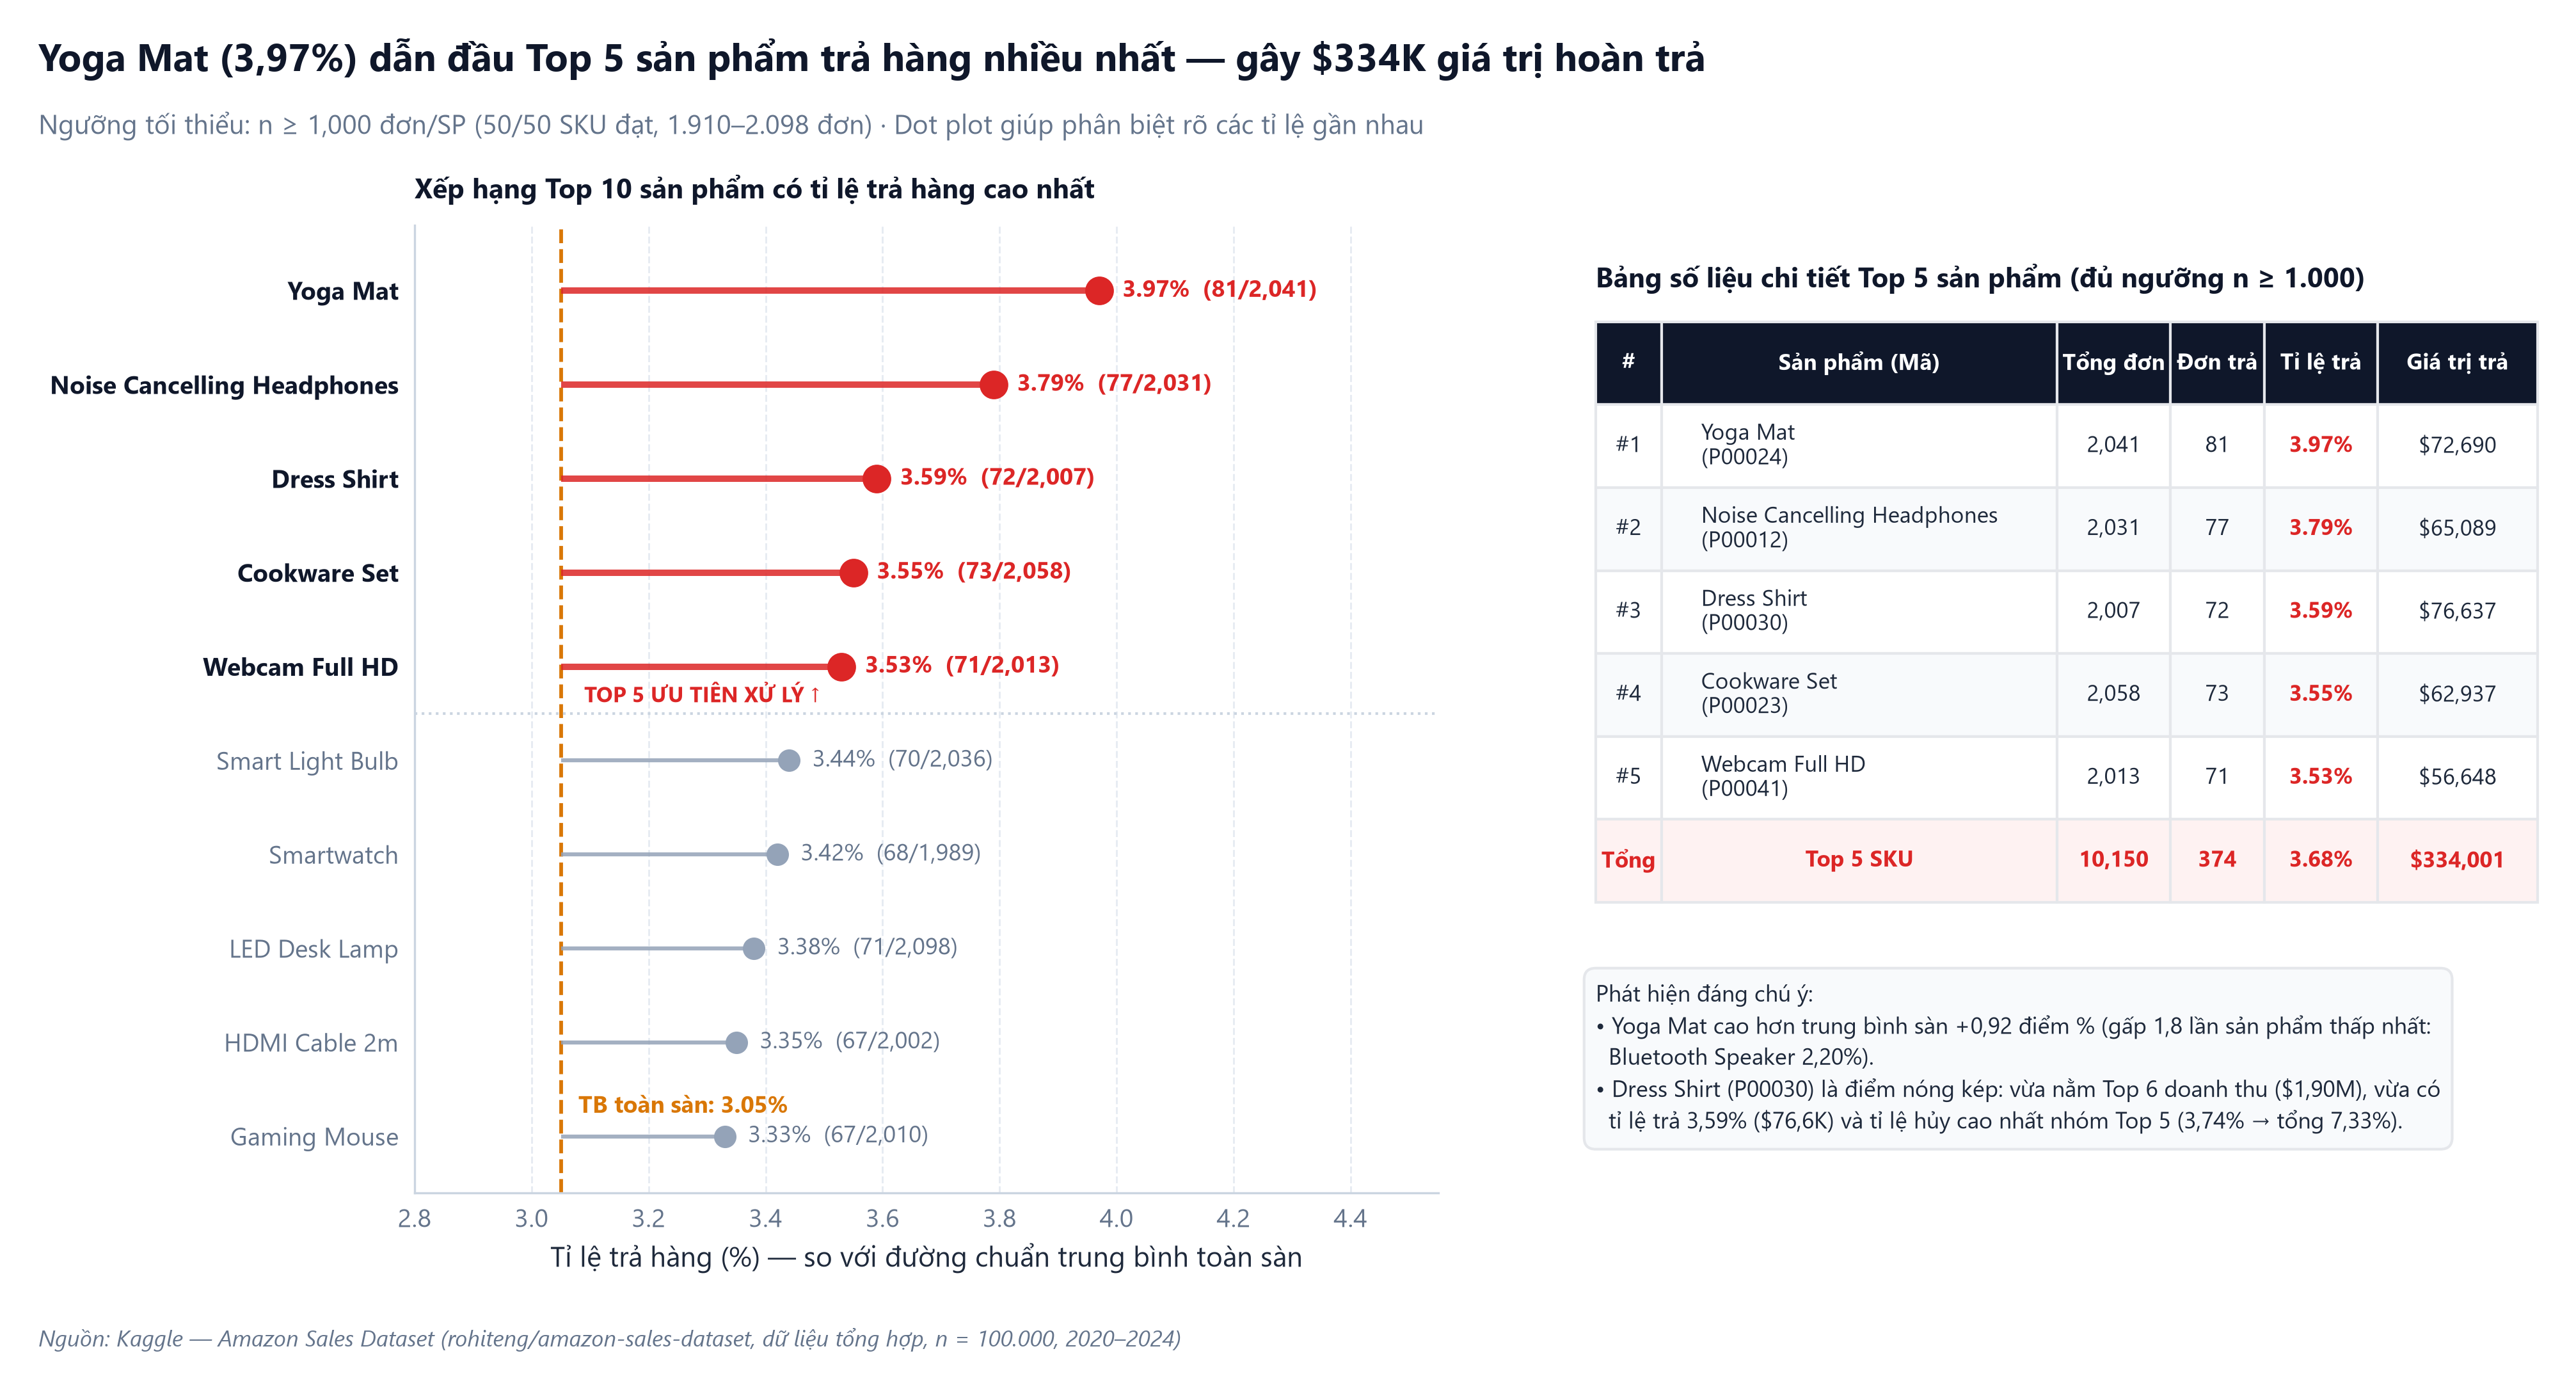

In [11]:
# Loc nguong n >= 1000 & hien thi Top 5 san pham tra hang cao nhat + ve Cau 9
top5_df = pd.DataFrame(kpis["q9"]["top5_returned"])[["ProductID", "ProductName", "orders", "returned", "return_pct", "cancel_pct", "return_rev"]]
display(top5_df.style.hide(axis="index").format({
    "orders": "{:,}", "returned": "{:,}", "return_pct": "{:.2f}%", "cancel_pct": "{:.2f}%", "return_rev": "${:,.0f}"
}))

p9 = mod_charts.plot_q9(df, kpis)
display(Image(filename=str(p9), width=940))

## Slide 13 · Câu 10 — Dashboard tổng hợp tương tác Plotly (TV6)
- **Nguyên tắc Shneiderman**: Tổng quan KPI (góc trên trái) → Lọc & phóng to (dropdown chọn năm + range slider) → Chi tiết (hover tooltip).
- **Mở bản toàn màn hình khi demo**: `outputs/dashboard/q10_dashboard.html` (file HTML độc lập chạy trực tiếp trên Chrome/Edge).

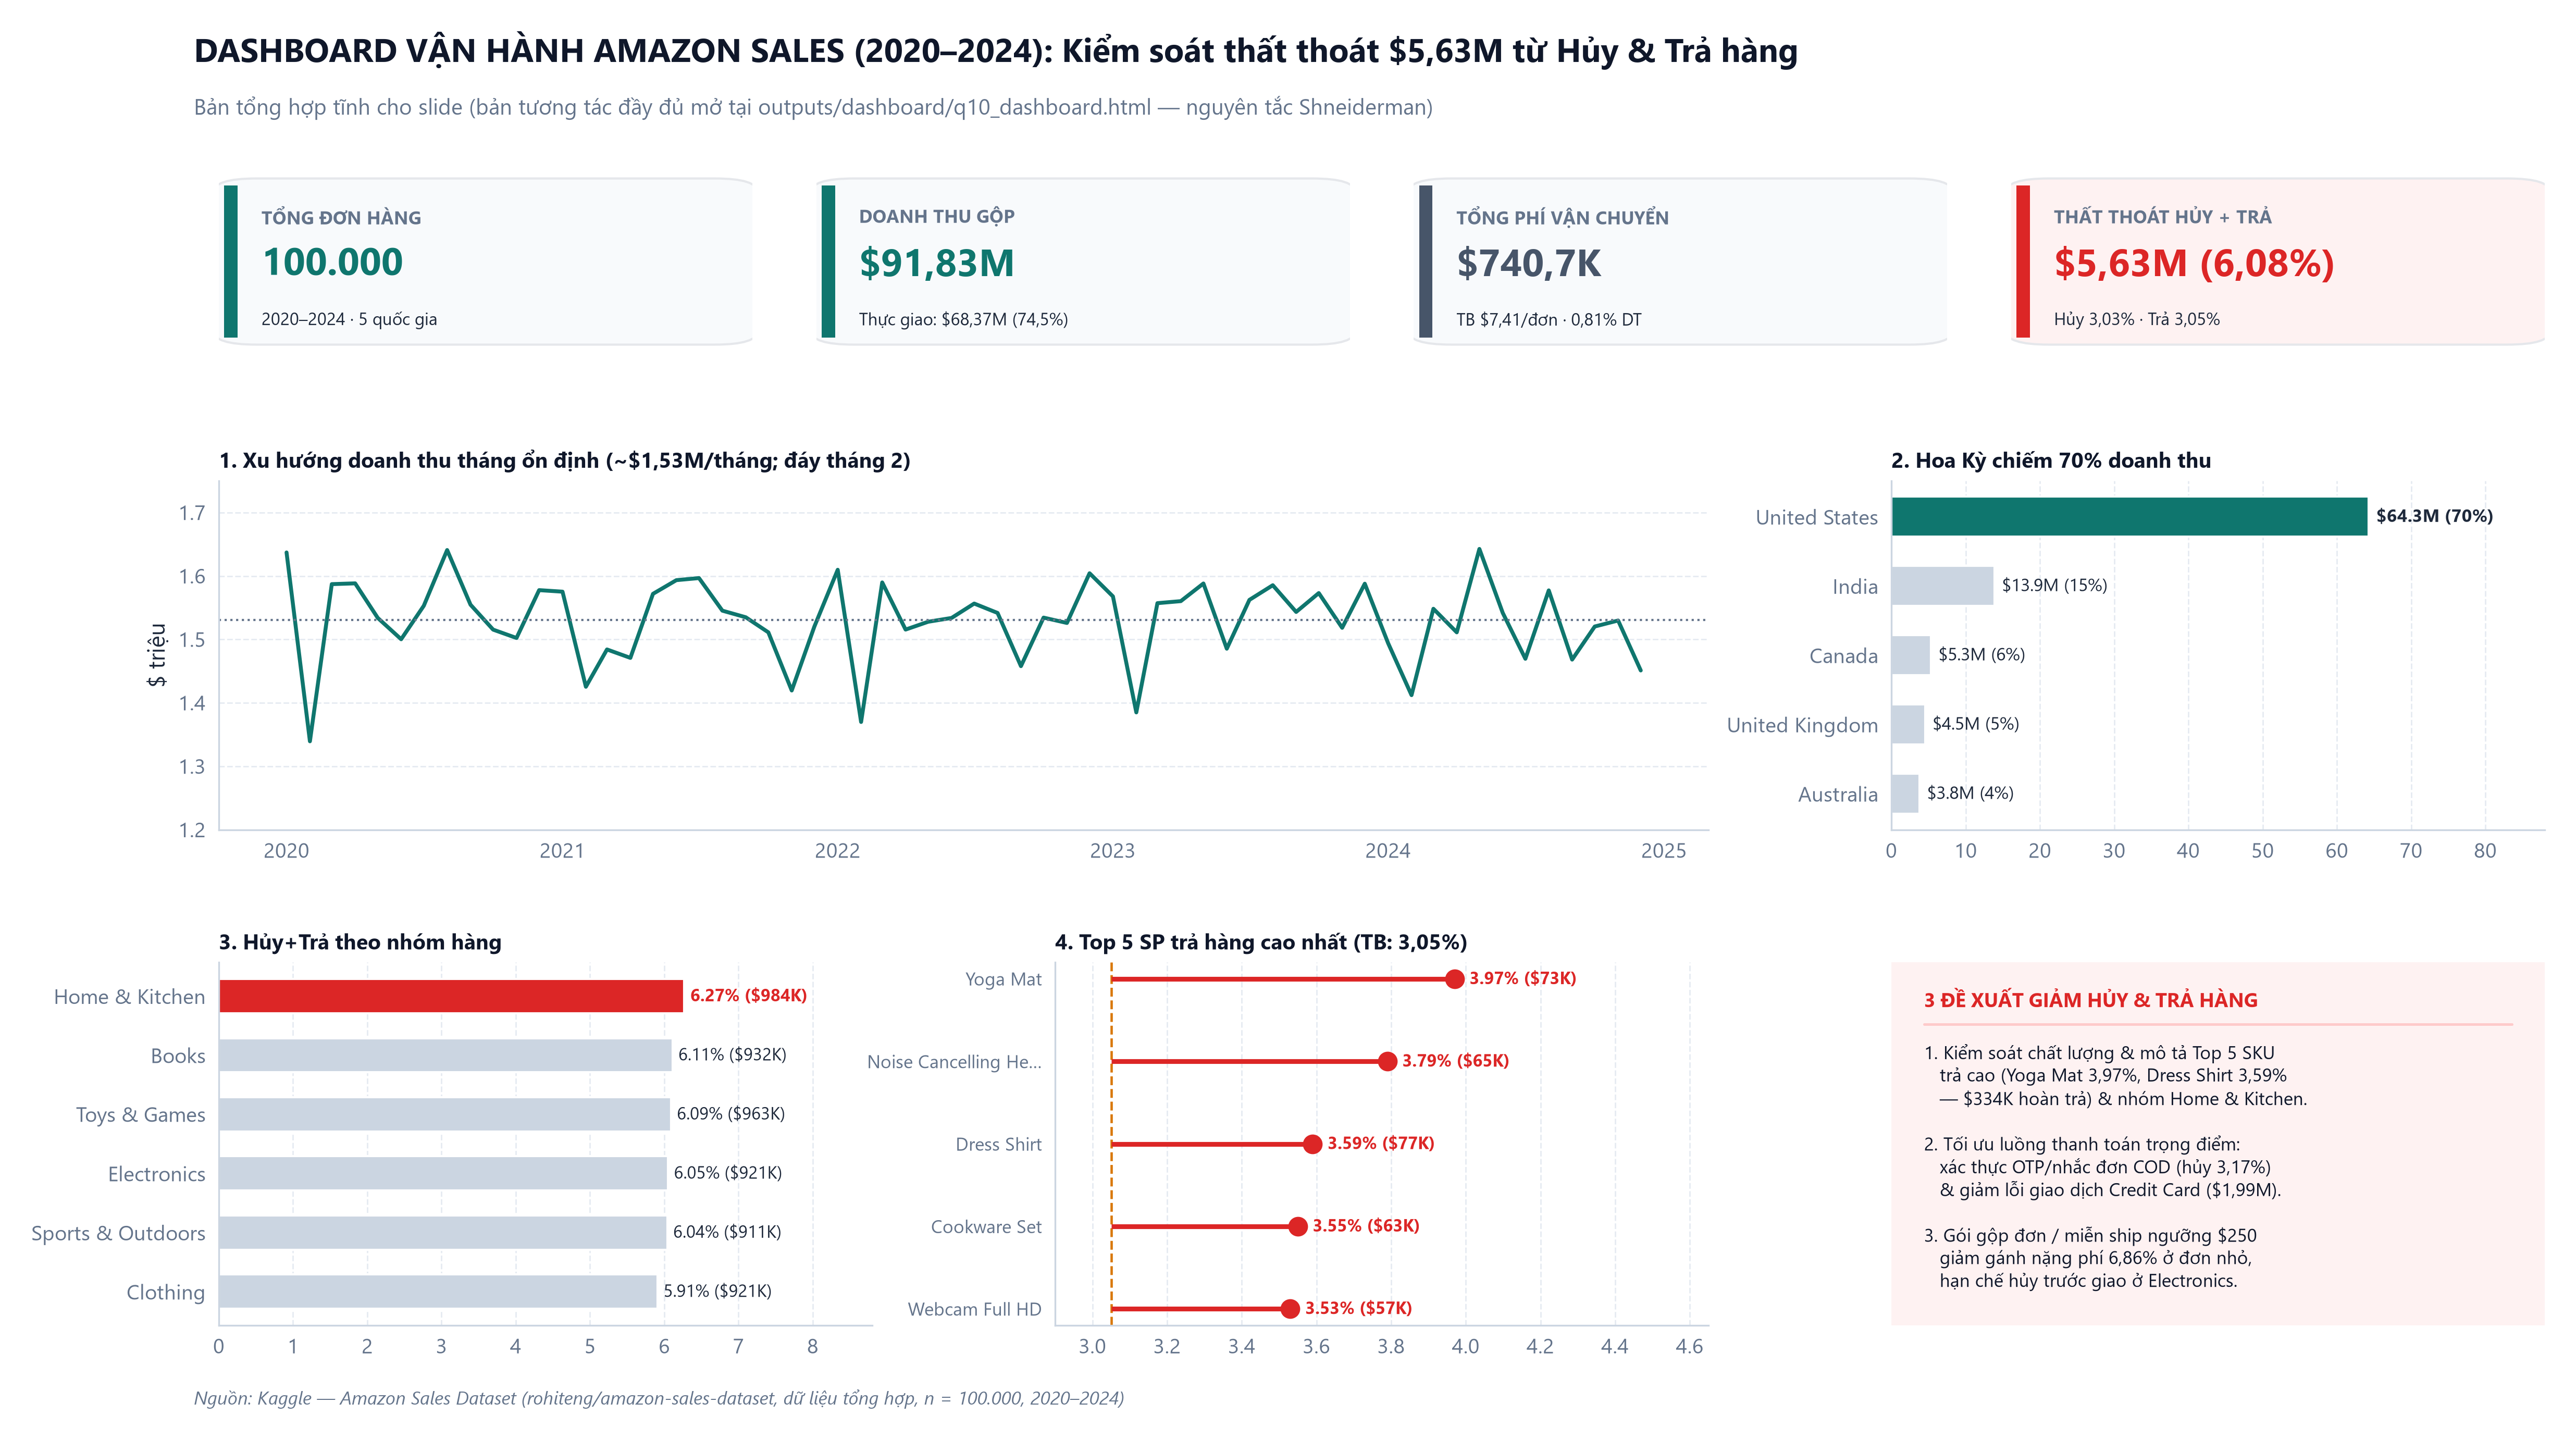

In [12]:
# 1) Hien thi ban Dashboard tinh tom tat 1 trang
p10 = mod_charts.plot_q10_static(df, kpis)
display(Image(filename=str(p10), width=980))

# 2) Demo tuong tac truc tiep ngay trong Notebook: Doanh thu thang co Dropdown chon Nam + Range Slider
ym_all = df.groupby(["Year", "YearMonth"]).agg(orders=("OrderID", "count"), revenue=("TotalAmount", "sum")).reset_index().sort_values("YearMonth")
years_opt = ["Tất cả (2020–2024)"] + [str(y) for y in sorted(df["Year"].unique())]

fig_dash = go.Figure()
fig_dash.add_trace(go.Scatter(
    x=ym_all["YearMonth"], y=ym_all["revenue"] / 1e6, mode="lines+markers", name="Tất cả",
    line=dict(color=COLORS["teal"], width=2.4), customdata=ym_all["orders"],
    hovertemplate="<b>%{x}</b><br>Doanh thu: $%{y:.2f}M<br>Số đơn: %{customdata:,}<extra></extra>",
))
for yr in sorted(df["Year"].unique()):
    sub = ym_all[ym_all["Year"] == yr]
    fig_dash.add_trace(go.Scatter(
        x=sub["YearMonth"], y=sub["revenue"] / 1e6, mode="lines+markers", name=str(yr), visible=False,
        line=dict(color=COLORS["teal"], width=2.8), customdata=sub["orders"],
        hovertemplate="<b>%{x}</b><br>Doanh thu: $%{y:.2f}M<br>Số đơn: %{customdata:,}<extra></extra>",
    ))

buttons = [dict(label=lbl, method="update", args=[{"visible": [j == i for j in range(len(years_opt))]}]) for i, lbl in enumerate(years_opt)]
fig_dash.update_layout(
    template="plotly_white", height=390,
    title="<b>Demo tương tác:</b> Chọn năm ở dropdown góc phải & kéo thanh trượt bên dưới",
    yaxis=dict(title="Doanh thu ($M)", range=[1.15, 1.78]),
    xaxis=dict(rangeslider=dict(visible=True, thickness=0.09)),
    updatemenus=[dict(buttons=buttons, direction="down", x=1.0, xanchor="right", y=1.18, yanchor="top")],
    margin=dict(l=55, r=20, t=72, b=30),
)
fig_dash.show()

dash_html = ROOT / "outputs" / "dashboard" / "q10_dashboard.html"
display(HTML(f'<p style="font-size:13px;">👉 <b>Mở Dashboard HTML toàn màn hình:</b> <code>{dash_html}</code></p>'))

## Slide 14 · 3 Đề xuất giảm Hủy & Trả hàng gắn số liệu (TV7)

| # | Đề xuất hành động | Bằng chứng từ số liệu | Tác động kỳ vọng |
|---|---|---|---|
| **1** | **Siết QC đóng gói & chuẩn hóa mô tả/size Top 5 SKU** | Top 5 SKU gây **\$334K** hoàn trả (`Yoga Mat` 3,97%, `Dress Shirt` 3,59% + hủy 3,74%); `Home & Kitchen` mất **\$984K** | Giảm 20% hoàn trả ở Top 5 SKU → cứu **~\$67K** |
| **2** | **Xác thực OTP cho COD & tối ưu luồng đổi hàng trên thẻ** | `COD` hủy cao nhất (**3,17%**); đơn hủy AOV cao nhất (**\$942**); `Credit + Debit Card` chiếm **55,1% (\$3,10M)** thiệt hại | Giảm 0,5 đpt tỉ lệ hủy toàn sàn → cứu **~\$460K** |
| **3** | **Gói gộp đơn Free-ship từ \$250 & rút ngắn xuất kho Electronics** | Đơn `<$250` chịu phí ship **6,86%** (gấp 18× đơn `>$1.5K`); `Electronics` hủy cao nhất (**3,23%**) | Tăng AOV đơn nhỏ & giảm hủy trước giao |

## Slide 15 · Kết luận, Hạn chế dữ liệu tổng hợp & Phản biện Q&A (TV7)

- **Kết luận chính**: Quy mô ổn định (**100.000 đơn · \$91,83M**), tập trung tại **Hoa Kỳ (70%)**; trọng tâm cải thiện nằm ở **\$5,63M (6,08%) thất thoát hủy & trả kéo dài 5 năm**.
- **Minh bạch hạn chế (*synthetic*)**: Không có mùa vụ thực tế; `City/State` Mỹ ghép ngẫu nhiên với 5 nước; `ProductName` gán độc lập `Category`; thiếu cột lý do trả hàng & thời gian giao.
- **Lời thoại chi tiết (11p30) & 12 câu Q&A phản biện**: Xem `docs/thuyet_trinh_va_qa.md` và `docs/slide_content.md`.

> *Cảm ơn Thầy/Cô và các bạn đã lắng nghe — Nhóm xin sẵn sàng trao đổi & phản biện!*